In [1]:
import os
import gc
import cv2
import json
import random
import shutil
import warnings
import platform

from pathlib import Path
from dataclasses import dataclass, asdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler,
)

from torchvision import transforms
from torchvision.transforms import InterpolationMode

from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights,
    swin_t,
    Swin_T_Weights,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    mean_absolute_error,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.13
PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


In [2]:
@dataclass
class Config:

    # ============================================================
    # EXPERIMENT
    # ============================================================

    TRAIN_SETTING: str = "DDR_APTOS"
    # Valid:
    # "DDR_APTOS"
    # "DDR"
    # "APTOS"

    SEED: int = 123

    EXPERIMENT_NAME: str = "MDFNet"

    # ============================================================
    # PATHS — CHANGE THESE FOR EACH KAGGLE PROFILE
    # ============================================================

    DDR_MANIFEST: str = "/kaggle/input/YOUR-DATASET/ddr_split_manifest.csv"
    APTOS_MANIFEST: str = "/kaggle/input/YOUR-DATASET/aptos_split_manifest.csv"

    DDR_IMAGE_ROOT: str = "/kaggle/input/YOUR-DDR-DATASET/"
    APTOS_IMAGE_ROOT: str = "/kaggle/input/YOUR-APTOS-DATASET/"

    WORK_ROOT: str = "/kaggle/working"

    # ============================================================
    # MODEL
    # ============================================================

    IMAGE_SIZE: int = 384
    NUM_CLASSES: int = 5

    PROJECTION_DIM: int = 512

    # Recovered setting from the completed MDF-Net configuration
    FEATURE_DROPOUT: float = 0.10

    CLASSIFIER_DROPOUT: float = 0.35

    # ============================================================
    # TRAINING
    # ============================================================

    BATCH_SIZE: int = 4
    GRAD_ACCUM_STEPS: int = 3

    NUM_WORKERS: int = 2

    MAX_EPOCHS: int = 25
    PATIENCE: int = 6

    EFFICIENTNET_LR: float = 4e-5
    SWIN_LR: float = 3e-5
    NEW_LAYERS_LR: float = 3e-4

    WEIGHT_DECAY: float = 1e-4

    LABEL_SMOOTHING: float = 0.02
    ORDINAL_LAMBDA: float = 0.15

    CLASS_WEIGHT_POWER: float = 0.50

    MAX_GRAD_NORM: float = 1.0

    ETA_MIN: float = 1e-6

    # ============================================================
    # PREPROCESSING
    # ============================================================

    BLACK_THRESHOLD: int = 10

    BEN_GRAHAM_SIGMA: float = 10.0

    JPEG_QUALITY: int = 95

    PREPROCESS_THREADS: int = 4

    # ============================================================
    # STATISTICS
    # ============================================================

    BOOTSTRAP_REPS: int = 2000
    BOOTSTRAP_CI: float = 0.95


CFG = Config()


assert CFG.TRAIN_SETTING in {
    "DDR_APTOS",
    "DDR",
    "APTOS",
}


RUN_NAME = (
    f"{CFG.EXPERIMENT_NAME}_"
    f"{CFG.TRAIN_SETTING}_"
    f"seed{CFG.SEED}"
)


WORK_DIR = (
    Path(CFG.WORK_ROOT)
    / RUN_NAME
)

CACHE_DIR = (
    WORK_DIR
    / "preprocessed_cache"
)


WORK_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

AMP_ENABLED = (
    DEVICE.type == "cuda"
)


CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "PDR",
]


print("Run:", RUN_NAME)
print("Setting:", CFG.TRAIN_SETTING)
print("Seed:", CFG.SEED)
print("Device:", DEVICE)
print("Output:", WORK_DIR)

Run: MDFNet_DDR_APTOS_seed123
Setting: DDR_APTOS
Seed: 123
Device: cuda
Output: /kaggle/working/MDFNet_DDR_APTOS_seed123


In [3]:
def seed_everything(seed):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    torch.use_deterministic_algorithms(
        True,
        warn_only=True,
    )


seed_everything(
    CFG.SEED
)

print("Seed fixed:", CFG.SEED)

Seed fixed: 123


In [6]:
# ============================================================
# ROBUST AUTO-DISCOVERY FOR NEW KAGGLE INPUT STRUCTURE
# ============================================================

from pathlib import Path
import pandas as pd

KAGGLE_INPUT = Path("/kaggle/input")

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
}


# ------------------------------------------------------------
# 1. Show directory structure
# ------------------------------------------------------------

print("=" * 80)
print("KAGGLE INPUT STRUCTURE")
print("=" * 80)

for path in sorted(KAGGLE_INPUT.rglob("*")):

    try:
        relative = path.relative_to(
            KAGGLE_INPUT
        )

        # Only show first few directory levels
        if (
            path.is_dir()
            and
            len(relative.parts) <= 4
        ):
            print(
                "   " * (len(relative.parts) - 1)
                + "📁 "
                + path.name
            )

    except Exception:
        pass


# ------------------------------------------------------------
# 2. Find every directory containing images
# ------------------------------------------------------------

def find_image_directories():

    candidates = []

    for folder in KAGGLE_INPUT.rglob("*"):

        if not folder.is_dir():
            continue

        try:
            images = [
                p
                for p in folder.iterdir()
                if p.is_file()
                and p.suffix.lower()
                in IMAGE_EXTENSIONS
            ]

        except Exception:
            continue

        if len(images) > 0:

            candidates.append(
                {
                    "path": folder,
                    "direct_images": len(images),
                    "name": folder.name.lower(),
                    "full_path": str(folder).lower(),
                }
            )

    return candidates


image_dirs = find_image_directories()


print("\n" + "=" * 80)
print("DIRECTORIES CONTAINING IMAGES")
print("=" * 80)

for item in image_dirs:

    print(
        f"{item['direct_images']:6d} images | "
        f"{item['path']}"
    )

KAGGLE INPUT STRUCTURE
📁 datasets
   📁 subhojitmitranit
      📁 aptos-dataset-full
         📁 test_images
         📁 train_images
      📁 single-ddr-dataset-full
         📁 archive
📁 notebooks
   📁 subhojitmitranit
      📁 aptos-training-for-journal
         📁 __results___files
         📁 aptos_efficientnet_b3
      📁 conference-paper
         📁 __results___files
         📁 ddr_efficientnet_b3

DIRECTORIES CONTAINING IMAGES
     4 images | /kaggle/input/notebooks/subhojitmitranit/conference-paper/__results___files
     4 images | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3
     5 images | /kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal/aptos_efficientnet_b3
     5 images | /kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal/__results___files
 12522 images | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/preprocessed_384_bg1
  3662 images | /kaggle/input/notebooks/subhojitmitranit/aptos-

In [7]:
# ============================================================
# 3. AUTOMATICALLY DETECT DDR AND APTOS ROOTS
# ============================================================

def score_dataset_root(
    folder,
    dataset_type,
):

    name = folder.name.lower()
    full = str(folder).lower()

    score = 0

    if dataset_type == "DDR":

        if "ddr" in name:
            score += 100

        if "ddr" in full:
            score += 50

        if "single" in full:
            score += 10


    elif dataset_type == "APTOS":

        if "aptos" in name:
            score += 100

        if "aptos" in full:
            score += 50

        if "blindness" in full:
            score += 20


    return score


def count_images_recursive(folder):

    try:

        return sum(
            1
            for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTENSIONS
        )

    except Exception:

        return 0


def find_dataset_root(
    dataset_type,
):

    candidates = []

    # Search ALL nested folders
    for folder in KAGGLE_INPUT.rglob("*"):

        if not folder.is_dir():
            continue

        score = score_dataset_root(
            folder,
            dataset_type,
        )

        if score == 0:
            continue

        image_count = (
            count_images_recursive(
                folder
            )
        )

        if image_count == 0:
            continue

        candidates.append(
            (
                score,
                image_count,
                folder,
            )
        )


    candidates.sort(
        key=lambda x: (
            x[0],
            x[1],
        ),
        reverse=True,
    )


    print(
        f"\n{dataset_type} candidates:"
    )

    for (
        score,
        image_count,
        folder,
    ) in candidates[:10]:

        print(
            f"score={score:3d} | "
            f"images={image_count:6d} | "
            f"{folder}"
        )


    if not candidates:
        return None


    return candidates[0][2]


DDR_ROOT = find_dataset_root(
    "DDR"
)

APTOS_ROOT = find_dataset_root(
    "APTOS"
)


print("\n" + "=" * 80)
print("FINAL DETECTED ROOTS")
print("=" * 80)

print(
    "DDR ROOT   :",
    DDR_ROOT
)

print(
    "APTOS ROOT :",
    APTOS_ROOT
)


if DDR_ROOT is None:

    raise RuntimeError(
        "DDR could not be detected. "
        "Check the directory listing above."
    )


if APTOS_ROOT is None:

    raise RuntimeError(
        "APTOS could not be detected. "
        "Check the directory listing above."
    )


DDR candidates:
score=160 | images= 12524 | /kaggle/input/datasets/subhojitmitranit/single-ddr-dataset-full
score=150 | images= 12526 | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3
score= 60 | images= 12524 | /kaggle/input/datasets/subhojitmitranit/single-ddr-dataset-full/archive
score= 60 | images= 12524 | /kaggle/input/datasets/subhojitmitranit/single-ddr-dataset-full/archive/DR_grading
score= 60 | images= 12524 | /kaggle/input/datasets/subhojitmitranit/single-ddr-dataset-full/archive/DR_grading/DR_grading
score= 50 | images= 12522 | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/preprocessed_384_bg1

APTOS candidates:
score=150 | images=  5590 | /kaggle/input/datasets/subhojitmitranit/aptos-dataset-full
score=150 | images=  3672 | /kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal
score=150 | images=  3667 | /kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal/aptos_efficientnet_b3
score

In [8]:
# ============================================================
# 4. FIND ALL CSV FILES INSIDE KAGGLE INPUT
# ============================================================

all_csv_files = list(
    KAGGLE_INPUT.rglob("*.csv")
)


print("=" * 80)
print("CSV FILES FOUND")
print("=" * 80)


for csv_path in all_csv_files:

    print(
        "\n📄",
        csv_path
    )

    try:

        temp = pd.read_csv(
            csv_path,
            nrows=5,
        )

        print(
            "Columns:",
            list(temp.columns)
        )

    except Exception as e:

        print(
            "Could not read:",
            e
        )

CSV FILES FOUND

📄 /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/validated_processed_manifest.csv
Columns: ['id_code', 'diagnosis', 'source_path', 'source_split', 'split', 'processed_path', 'preprocess_error']

📄 /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/split_manifest.csv
Columns: ['id_code', 'diagnosis', 'source_path', 'split']

📄 /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/training_history.csv
Columns: ['epoch', 'train_loss', 'train_accuracy', 'val_accuracy', 'val_balanced_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_qwk', 'val_macro_roc_auc_ovr', 'val_loss', 'selection_score', 'backbone_lr', 'head_lr', 'epoch_seconds']

📄 /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/test_predictions.csv
Columns: ['id_code', 'true_label', 'predicted_label', 'prob_0_No_DR', 'prob_1_Mild_NPDR', 'prob_2_Moderate_NPDR', 'prob_3_Severe_NPDR',

In [10]:
# ============================================================
# 5. DETECT FIXED SPLIT MANIFESTS
# ============================================================

def detect_split_manifest(
    domain,
):

    candidates = []


    for csv_path in all_csv_files:

        try:

            df = pd.read_csv(
                csv_path,
                nrows=20,
            )

        except Exception:

            continue


        columns = {
            str(c)
            .strip()
            .lower()

            for c
            in df.columns
        }


        filename = (
            csv_path.name.lower()
        )

        full_path = (
            str(csv_path).lower()
        )


        score = 0


        # Most important:
        # exact columns used in our experiments
        if {
            "id_code",
            "diagnosis",
            "split",
        }.issubset(columns):

            score += 500


        if "source_path" in columns:
            score += 50


        if "manifest" in filename:
            score += 40


        if "split" in filename:
            score += 30


        if domain == "DDR":

            if "ddr" in full_path:
                score += 100


        elif domain == "APTOS":

            if "aptos" in full_path:
                score += 100


        if score > 0:

            candidates.append(
                (
                    score,
                    csv_path,
                    columns,
                )
            )


    candidates.sort(
        key=lambda x: x[0],
        reverse=True,
    )


    print(
        f"\n{domain} manifest candidates:"
    )


    for (
        score,
        path,
        columns,
    ) in candidates[:10]:

        print(
            f"score={score:3d} | "
            f"{path}"
        )

        print(
            "   ",
            sorted(columns)
        )


    for (
        score,
        path,
        columns,
    ) in candidates:

        if {
            "id_code",
            "diagnosis",
            "split",
        }.issubset(columns):

            return path


    return None


DDR_MANIFEST = (
    detect_split_manifest(
        "DDR"
    )
)


APTOS_MANIFEST = (
    detect_split_manifest(
        "APTOS"
    )
)


print("\n" + "=" * 80)
print("SELECTED MANIFESTS")
print("=" * 80)

print(
    "DDR manifest:",
    DDR_MANIFEST
)

print(
    "APTOS manifest:",
    APTOS_MANIFEST
)


DDR manifest candidates:
score=720 | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/split_manifest.csv
    ['diagnosis', 'id_code', 'source_path', 'split']
score=690 | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/validated_processed_manifest.csv
    ['diagnosis', 'id_code', 'preprocess_error', 'processed_path', 'source_path', 'source_split', 'split']
score=620 | /kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal/aptos_efficientnet_b3/split_manifest.csv
    ['diagnosis', 'id_code', 'source_dataset', 'source_path', 'split']
score=590 | /kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal/aptos_efficientnet_b3/validated_processed_manifest.csv
    ['diagnosis', 'id_code', 'preprocess_error', 'processed_path', 'source_dataset', 'source_path', 'split']
score=100 | /kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/training_history.csv
    ['backbone_lr', 'epoch', 'epoch

In [11]:
# ============================================================
# 6. UPDATE CONFIG WITH DISCOVERED PATHS
# ============================================================

CFG.DDR_IMAGE_ROOT = str(
    DDR_ROOT
)

CFG.APTOS_IMAGE_ROOT = str(
    APTOS_ROOT
)


if DDR_MANIFEST is not None:

    CFG.DDR_MANIFEST = str(
        DDR_MANIFEST
    )


if APTOS_MANIFEST is not None:

    CFG.APTOS_MANIFEST = str(
        APTOS_MANIFEST
    )


print("=" * 80)
print("FINAL PATH CONFIGURATION")
print("=" * 80)

print(
    "\nDDR IMAGE ROOT"
)

print(
    CFG.DDR_IMAGE_ROOT
)


print(
    "\nAPTOS IMAGE ROOT"
)

print(
    CFG.APTOS_IMAGE_ROOT
)


print(
    "\nDDR MANIFEST"
)

print(
    getattr(
        CFG,
        "DDR_MANIFEST",
        None,
    )
)


print(
    "\nAPTOS MANIFEST"
)

print(
    getattr(
        CFG,
        "APTOS_MANIFEST",
        None,
    )
)

FINAL PATH CONFIGURATION

DDR IMAGE ROOT
/kaggle/input/datasets/subhojitmitranit/single-ddr-dataset-full

APTOS IMAGE ROOT
/kaggle/input/datasets/subhojitmitranit/aptos-dataset-full

DDR MANIFEST
/kaggle/input/notebooks/subhojitmitranit/conference-paper/ddr_efficientnet_b3/split_manifest.csv

APTOS MANIFEST
/kaggle/input/notebooks/subhojitmitranit/aptos-training-for-journal/aptos_efficientnet_b3/split_manifest.csv


In [12]:
# ============================================================
# BUILD DDR + APTOS IMAGE INDEXES
# ============================================================

from pathlib import Path
from tqdm.auto import tqdm

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
}


def build_image_index(root):

    root = Path(root)

    image_files = [
        p
        for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]

    if len(image_files) == 0:

        raise RuntimeError(
            f"No images found inside:\n{root}"
        )

    index = {}

    for p in tqdm(
        image_files,
        desc=f"Indexing {root.name}",
    ):

        # Exact filename
        index[p.name] = str(p)

        # Filename without extension
        index[p.stem] = str(p)

    print(
        f"✅ {root.name}: "
        f"{len(image_files):,} images indexed"
    )

    return index


ddr_index = build_image_index(
    CFG.DDR_IMAGE_ROOT
)

aptos_index = build_image_index(
    CFG.APTOS_IMAGE_ROOT
)

Indexing single-ddr-dataset-full:   0%|          | 0/12524 [00:00<?, ?it/s]

✅ single-ddr-dataset-full: 12,524 images indexed


Indexing aptos-dataset-full:   0%|          | 0/5590 [00:00<?, ?it/s]

✅ aptos-dataset-full: 5,590 images indexed


In [13]:
# ============================================================
# LOAD FIXED DDR + APTOS SPLIT MANIFESTS
# ============================================================

import pandas as pd


def load_fixed_manifest(
    manifest_path,
    domain,
    image_index,
):

    df = pd.read_csv(
        manifest_path
    ).copy()

    print(
        f"\n{domain} manifest columns:",
        list(df.columns)
    )

    required_columns = {
        "id_code",
        "diagnosis",
        "split",
    }

    missing = (
        required_columns
        - set(df.columns)
    )

    if missing:

        raise ValueError(
            f"{domain} manifest missing: {missing}"
        )

    df["diagnosis"] = (
        df["diagnosis"]
        .astype(int)
    )

    df["domain"] = domain


    def resolve_image_path(row):

        # Old absolute path may no longer work
        # on this notebook/profile.
        if "source_path" in row.index:

            old_path = Path(
                str(
                    row["source_path"]
                )
            )

            if old_path.exists():
                return str(old_path)


        image_id = str(
            row["id_code"]
        )

        possible_keys = [
            image_id,
            Path(image_id).name,
            Path(image_id).stem,
        ]


        for key in possible_keys:

            if key in image_index:
                return image_index[key]


        raise FileNotFoundError(
            f"{domain} image not found: "
            f"{image_id}"
        )


    df["source_path"] = (
        df.apply(
            resolve_image_path,
            axis=1,
        )
    )

    return df


ddr_df = load_fixed_manifest(
    CFG.DDR_MANIFEST,
    "DDR",
    ddr_index,
)


aptos_df = load_fixed_manifest(
    CFG.APTOS_MANIFEST,
    "APTOS",
    aptos_index,
)


print("\n✅ DDR loaded:", len(ddr_df))
print("✅ APTOS loaded:", len(aptos_df))


DDR manifest columns: ['id_code', 'diagnosis', 'source_path', 'split']

APTOS manifest columns: ['id_code', 'diagnosis', 'source_dataset', 'source_path', 'split']

✅ DDR loaded: 12522
✅ APTOS loaded: 3662


In [14]:
# ============================================================
# VERIFY THE EXACT LOCKED SPLITS
# ============================================================

EXPECTED_DDR = {
    "train": 8765,
    "val": 1878,
    "test": 1879,
}

EXPECTED_APTOS = {
    "train": 2563,
    "val": 549,
    "test": 550,
}


print("=" * 60)
print("DDR SPLITS")
print("=" * 60)

for split, expected in EXPECTED_DDR.items():

    actual = int(
        (
            ddr_df["split"]
            == split
        ).sum()
    )

    print(
        f"{split:5s}: "
        f"{actual:,} "
        f"(expected {expected:,})"
    )

    assert actual == expected


print("\n" + "=" * 60)
print("APTOS SPLITS")
print("=" * 60)

for split, expected in EXPECTED_APTOS.items():

    actual = int(
        (
            aptos_df["split"]
            == split
        ).sum()
    )

    print(
        f"{split:5s}: "
        f"{actual:,} "
        f"(expected {expected:,})"
    )

    assert actual == expected


assert set(
    ddr_df["diagnosis"].unique()
) <= set(range(5))

assert set(
    aptos_df["diagnosis"].unique()
) <= set(range(5))


print(
    "\n✅ Exact experiment splits verified."
)

DDR SPLITS
train: 8,765 (expected 8,765)
val  : 1,878 (expected 1,878)
test : 1,879 (expected 1,879)

APTOS SPLITS
train: 2,563 (expected 2,563)
val  : 549 (expected 549)
test : 550 (expected 550)

✅ Exact experiment splits verified.


In [15]:
# ============================================================
# FINAL RUN SETUP
# Run AFTER path discovery + split verification
# ============================================================

from pathlib import Path
import os
import json
import random
import shutil
import platform
import warnings
import gc
import cv2

import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")


# ============================================================
# IMPORTANT:
# Check these before running.
# ============================================================

print("TRAIN_SETTING :", CFG.TRAIN_SETTING)
print("SEED          :", CFG.SEED)

assert CFG.TRAIN_SETTING in {
    "DDR_APTOS",
    "DDR",
    "APTOS",
}


RUN_NAME = (
    f"MDFNet_"
    f"{CFG.TRAIN_SETTING}_"
    f"seed{CFG.SEED}"
)

WORK_DIR = (
    Path("/kaggle/working")
    / RUN_NAME
)

WORK_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Keep preprocessing outside RUN_NAME.
# This allows another experiment in the same Kaggle session
# to reuse the processed images.
CACHE_DIR = Path(
    "/kaggle/working/"
    "MDFNet_preprocessed_384"
)

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

AMP_ENABLED = (
    DEVICE.type == "cuda"
)


CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "PDR",
]


print("\nRUN NAME :", RUN_NAME)
print("DEVICE   :", DEVICE)
print("WORK DIR :", WORK_DIR)
print("CACHE    :", CACHE_DIR)

if torch.cuda.is_available():
    print(
        "GPU      :",
        torch.cuda.get_device_name(0)
    )

TRAIN_SETTING : DDR_APTOS
SEED          : 123

RUN NAME : MDFNet_DDR_APTOS_seed123
DEVICE   : cuda
WORK DIR : /kaggle/working/MDFNet_DDR_APTOS_seed123
CACHE    : /kaggle/working/MDFNet_preprocessed_384
GPU      : Tesla T4


In [16]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

def seed_everything(seed):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    torch.use_deterministic_algorithms(
        True,
        warn_only=True
    )


seed_everything(
    CFG.SEED
)

print(
    "✅ Seed fixed:",
    CFG.SEED
)

✅ Seed fixed: 123


In [17]:
# ============================================================
# RETINAL PREPROCESSING
# ============================================================

def read_rgb(path):

    bgr = cv2.imread(
        str(path),
        cv2.IMREAD_COLOR
    )

    if bgr is None:

        raise ValueError(
            f"OpenCV failed to read: {path}"
        )

    return cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )


def crop_black_border(
    image,
    threshold=10
):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    mask = (
        gray > threshold
    )

    if not mask.any():
        return image

    ys, xs = np.where(
        mask
    )

    y0 = int(
        ys.min()
    )

    y1 = int(
        ys.max()
    ) + 1

    x0 = int(
        xs.min()
    )

    x1 = int(
        xs.max()
    ) + 1

    cropped = image[
        y0:y1,
        x0:x1
    ]

    if cropped.size == 0:
        return image

    return cropped


def pad_to_square(image):

    height, width = (
        image.shape[:2]
    )

    side = max(
        height,
        width
    )

    canvas = np.zeros(
        (
            side,
            side,
            3
        ),
        dtype=np.uint8
    )

    y0 = (
        side - height
    ) // 2

    x0 = (
        side - width
    ) // 2

    canvas[
        y0:y0 + height,
        x0:x0 + width
    ] = image

    return canvas


def ben_graham_enhance(
    image,
    sigma=10.0
):

    blurred = cv2.GaussianBlur(
        image,
        (0, 0),
        sigmaX=sigma,
        sigmaY=sigma
    )

    enhanced = cv2.addWeighted(
        image,
        4.0,
        blurred,
        -4.0,
        128.0
    )

    return enhanced


def preprocess_retina(path):

    image = read_rgb(
        path
    )

    image = crop_black_border(
        image,
        threshold=10
    )

    image = pad_to_square(
        image
    )

    image = cv2.resize(
        image,
        (
            384,
            384
        ),
        interpolation=cv2.INTER_AREA
    )

    image = ben_graham_enhance(
        image,
        sigma=10.0
    )

    return image


print(
    "✅ Preprocessing functions ready"
)

✅ Preprocessing functions ready


In [18]:
# ============================================================
# COMBINE MANIFESTS
# ============================================================

all_df = pd.concat(
    [
        ddr_df,
        aptos_df
    ],
    ignore_index=True
)


print(
    "DDR rows   :",
    len(ddr_df)
)

print(
    "APTOS rows :",
    len(aptos_df)
)

print(
    "Total rows :",
    len(all_df)
)


display(
    all_df[
        [
            "id_code",
            "diagnosis",
            "split",
            "domain",
            "source_path"
        ]
    ].head()
)

DDR rows   : 12522
APTOS rows : 3662
Total rows : 16184


,id_code,diagnosis,split,domain,source_path
0,007-0009-000.jpg,0,test,DDR,/kaggle/input/datasets/subhojitmitranit/single...
1,007-0023-000.jpg,0,test,DDR,/kaggle/input/datasets/subhojitmitranit/single...
2,007-0024-000.jpg,0,test,DDR,/kaggle/input/datasets/subhojitmitranit/single...
3,007-0030-000.jpg,0,test,DDR,/kaggle/input/datasets/subhojitmitranit/single...
4,007-0037-000.jpg,0,test,DDR,/kaggle/input/datasets/subhojitmitranit/single...


In [19]:
# ============================================================
# PREPROCESS + CACHE
# ============================================================

from concurrent.futures import (
    ThreadPoolExecutor,
    as_completed
)


JPEG_QUALITY = 95
PREPROCESS_THREADS = 4


def make_cache_path(row):

    image_id = Path(
        str(
            row["id_code"]
        )
    ).stem

    filename = (
        f"{row['domain']}"
        f"__{image_id}.jpg"
    )

    return (
        CACHE_DIR
        / filename
    )


def preprocess_one(row):

    destination = (
        make_cache_path(row)
    )

    if (
        destination.exists()
        and destination.stat().st_size > 0
    ):

        return (
            str(destination),
            None
        )

    try:

        image = preprocess_retina(
            row["source_path"]
        )

        bgr = cv2.cvtColor(
            image,
            cv2.COLOR_RGB2BGR
        )

        ok, encoded = cv2.imencode(
            ".jpg",
            bgr,
            [
                int(
                    cv2.IMWRITE_JPEG_QUALITY
                ),
                JPEG_QUALITY
            ]
        )

        if not ok:

            raise ValueError(
                "JPEG encoding failed"
            )

        encoded.tofile(
            destination
        )

        return (
            str(destination),
            None
        )

    except Exception as exc:

        return (
            "",
            f"{type(exc).__name__}: {exc}"
        )


records = (
    all_df
    .to_dict("records")
)

results = [
    None
] * len(records)


with ThreadPoolExecutor(
    max_workers=PREPROCESS_THREADS
) as executor:

    futures = {

        executor.submit(
            preprocess_one,
            row
        ): i

        for i, row
        in enumerate(records)
    }

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Preprocessing retinal images"
    ):

        idx = futures[
            future
        ]

        results[idx] = (
            future.result()
        )


all_df[
    "processed_path"
] = [

    item[0]
    for item in results
]


all_df[
    "preprocess_error"
] = [

    item[1]
    for item in results
]


failed = all_df[
    all_df[
        "preprocess_error"
    ].notna()
].copy()


print(
    "\nFailures:",
    len(failed)
)


if len(failed) > 0:

    display(
        failed[
            [
                "domain",
                "id_code",
                "source_path",
                "preprocess_error"
            ]
        ].head(30)
    )

    raise RuntimeError(
        "❌ Preprocessing failure detected. "
        "Do NOT continue to training."
    )


all_df.to_csv(
    WORK_DIR
    /
    "processed_manifest.csv",
    index=False
)


print(
    "\n✅ Valid processed images:",
    len(all_df)
)

Preprocessing retinal images:   0%|          | 0/16184 [00:00<?, ?it/s]

Corrupt JPEG data: 35 extraneous bytes before marker 0xd9
Corrupt JPEG data: 38 extraneous bytes before marker 0xd9
Corrupt JPEG data: 34 extraneous bytes before marker 0xd9



Failures: 0

✅ Valid processed images: 16184


In [20]:
# ============================================================
# CACHE VALIDATION
# ============================================================

missing_processed = [

    p
    for p in all_df[
        "processed_path"
    ]

    if not Path(p).exists()
]


print(
    "Missing cached images:",
    len(missing_processed)
)


assert (
    len(missing_processed)
    == 0
)


print(
    "✅ Processed-image cache verified"
)

Missing cached images: 0
✅ Processed-image cache verified


In [21]:
# ============================================================
# AUGMENTATION + NORMALIZATION
# ============================================================

from torchvision import transforms

from torchvision.transforms import (
    InterpolationMode
)


IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform = (
    transforms.Compose(
        [

            transforms.RandomHorizontalFlip(
                p=0.5
            ),

            transforms.RandomAffine(
                degrees=15,

                translate=(
                    0.03,
                    0.03
                ),

                scale=(
                    0.95,
                    1.05
                ),

                interpolation=
                    InterpolationMode.BILINEAR,

                fill=0
            ),

            transforms.ColorJitter(
                brightness=0.12,
                contrast=0.12,
                saturation=0.05,
                hue=0.02
            ),

            transforms.ToTensor(),

            transforms.Normalize(
                IMAGENET_MEAN,
                IMAGENET_STD
            )
        ]
    )
)


eval_transform = (
    transforms.Compose(
        [

            transforms.ToTensor(),

            transforms.Normalize(
                IMAGENET_MEAN,
                IMAGENET_STD
            )
        ]
    )
)


print(
    "✅ Transform pipelines ready"
)

✅ Transform pipelines ready


In [22]:
# ============================================================
# DATASET CLASS
# ============================================================

from torch.utils.data import (
    Dataset
)


class FundusDataset(Dataset):

    def __init__(
        self,
        frame,
        transform=None
    ):

        self.frame = (
            frame
            .reset_index(drop=True)
            .copy()
        )

        self.transform = (
            transform
        )


    def __len__(self):

        return len(
            self.frame
        )


    def __getitem__(
        self,
        index
    ):

        row = (
            self.frame
            .iloc[index]
        )

        image = Image.open(
            row[
                "processed_path"
            ]
        ).convert(
            "RGB"
        )

        if (
            self.transform
            is not None
        ):

            image = (
                self.transform(
                    image
                )
            )

        label = int(
            row[
                "diagnosis"
            ]
        )

        return {

            "image":
                image,

            "label":
                label,

            "id_code":
                str(
                    row[
                        "id_code"
                    ]
                ),

            "domain":
                str(
                    row[
                        "domain"
                    ]
                )
        }


print(
    "✅ Dataset class ready"
)

✅ Dataset class ready


In [23]:
# ============================================================
# DOMAIN-SPECIFIC SPLIT DATAFRAMES
# ============================================================

ddr_processed = all_df[
    all_df[
        "domain"
    ] == "DDR"
].copy()


aptos_processed = all_df[
    all_df[
        "domain"
    ] == "APTOS"
].copy()


def select_split(
    frame,
    split
):

    return (
        frame[
            frame[
                "split"
            ] == split
        ]
        .reset_index(
            drop=True
        )
    )


ddr_train = select_split(
    ddr_processed,
    "train"
)

ddr_val = select_split(
    ddr_processed,
    "val"
)

ddr_test = select_split(
    ddr_processed,
    "test"
)


aptos_train = select_split(
    aptos_processed,
    "train"
)

aptos_val = select_split(
    aptos_processed,
    "val"
)

aptos_test = select_split(
    aptos_processed,
    "test"
)


print(
    "DDR:",
    len(ddr_train),
    len(ddr_val),
    len(ddr_test)
)

print(
    "APTOS:",
    len(aptos_train),
    len(aptos_val),
    len(aptos_test)
)

DDR: 8765 1878 1879
APTOS: 2563 549 550


In [24]:
# ============================================================
# SELECT TRAINING SET
# ============================================================

if (
    CFG.TRAIN_SETTING
    == "DDR_APTOS"
):

    train_df = pd.concat(
        [
            ddr_train,
            aptos_train
        ],
        ignore_index=True
    )


elif (
    CFG.TRAIN_SETTING
    == "DDR"
):

    train_df = (
        ddr_train
        .copy()
    )


elif (
    CFG.TRAIN_SETTING
    == "APTOS"
):

    train_df = (
        aptos_train
        .copy()
    )


else:

    raise ValueError(
        CFG.TRAIN_SETTING
    )


print(
    "Training setting:",
    CFG.TRAIN_SETTING
)

print(
    "Training images:",
    len(train_df)
)


print(
    "\nDomain counts:"
)

display(
    train_df[
        "domain"
    ].value_counts()
)


print(
    "\nClass counts:"
)

display(
    train_df[
        "diagnosis"
    ]
    .value_counts()
    .sort_index()
)

Training setting: DDR_APTOS
Training images: 11328

Domain counts:


domain
DDR      8765
APTOS    2563
Name: count, dtype: int64


Class counts:


diagnosis
0    5649
1     700
2    3833
3     300
4     846
Name: count, dtype: int64

In [25]:
# ============================================================
# CLASS WEIGHTS
# w_c ~ inverse frequency ^ 0.5
# ============================================================

NUM_CLASSES = 5

CLASS_WEIGHT_POWER = 0.50


class_counts = np.bincount(
    train_df[
        "diagnosis"
    ].values,
    minlength=NUM_CLASSES
)


class_weights = (

    class_counts.sum()
    /
    np.maximum(
        class_counts,
        1
    )

) ** CLASS_WEIGHT_POWER


# Normalize mean to 1
class_weights = (

    class_weights
    /
    class_weights.mean()
)


CLASS_WEIGHTS_TENSOR = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)


print(
    "Class counts:"
)

for i, n in enumerate(
    class_counts
):

    print(
        CLASS_NAMES[i],
        ":",
        int(n)
    )


print(
    "\nLoss weights:"
)

for i, w in enumerate(
    class_weights
):

    print(
        CLASS_NAMES[i],
        ":",
        round(
            float(w),
            5
        )
    )

Class counts:
No DR : 5649
Mild : 700
Moderate : 3833
Severe : 300
PDR : 846

Loss weights:
No DR : 0.41743
Mild : 1.18581
Moderate : 0.50675
Severe : 1.81136
PDR : 1.07865


In [26]:
# ============================================================
# DOMAIN + CLASS BALANCED SAMPLER
# ============================================================

from torch.utils.data import (
    WeightedRandomSampler
)


sample_weights = np.zeros(
    len(train_df),
    dtype=np.float64
)


if (
    CFG.TRAIN_SETTING
    == "DDR_APTOS"
):

    domain_class_counts = (

        train_df
        .groupby(
            [
                "domain",
                "diagnosis"
            ]
        )
        .size()
        .to_dict()
    )


    print(
        "Domain-class counts:"
    )

    for key, value in (
        domain_class_counts.items()
    ):

        print(
            key,
            ":",
            value
        )


    for i, row in (
        train_df.iterrows()
    ):

        n_dc = (
            domain_class_counts[
                (
                    row[
                        "domain"
                    ],
                    int(
                        row[
                            "diagnosis"
                        ]
                    )
                )
            ]
        )

        sample_weights[i] = (
            1.0
            /
            np.sqrt(
                n_dc
            )
        )


    # Equal total sampling mass:
    # DDR = 0.5
    # APTOS = 0.5
    for domain in [
        "DDR",
        "APTOS"
    ]:

        idx = np.where(
            train_df[
                "domain"
            ].values
            == domain
        )[0]

        domain_mass = (
            sample_weights[
                idx
            ].sum()
        )

        sample_weights[
            idx
        ] *= (
            0.5
            /
            domain_mass
        )


    print(
        "\nSampling probability mass:"
    )

    for domain in [
        "DDR",
        "APTOS"
    ]:

        mask = (
            train_df[
                "domain"
            ].values
            == domain
        )

        print(
            domain,
            ":",
            sample_weights[
                mask
            ].sum()
        )


else:

    class_count_dict = (

        train_df[
            "diagnosis"
        ]
        .value_counts()
        .to_dict()
    )


    for i, row in (
        train_df.iterrows()
    ):

        n_c = (
            class_count_dict[
                int(
                    row[
                        "diagnosis"
                    ]
                )
            ]
        )

        sample_weights[i] = (
            1.0
            /
            np.sqrt(
                n_c
            )
        )


SAMPLER_GENERATOR = (
    torch.Generator()
)

SAMPLER_GENERATOR.manual_seed(
    CFG.SEED
)


train_sampler = (
    WeightedRandomSampler(

        weights=torch.tensor(
            sample_weights,
            dtype=torch.double
        ),

        num_samples=len(
            train_df
        ),

        replacement=True,

        generator=
            SAMPLER_GENERATOR
    )
)


print(
    "\n✅ Weighted sampler ready"
)

Domain-class counts:
('APTOS', 0) : 1263
('APTOS', 1) : 259
('APTOS', 2) : 699
('APTOS', 3) : 135
('APTOS', 4) : 207
('DDR', 0) : 4386
('DDR', 1) : 441
('DDR', 2) : 3134
('DDR', 3) : 165
('DDR', 4) : 639

Sampling probability mass:
DDR : 0.49999999999999994
APTOS : 0.5

✅ Weighted sampler ready


In [100]:
# ============================================================
# DATALOADERS — FINAL STABLE VERSION
# ============================================================

from torch.utils.data import DataLoader


BATCH_SIZE = 4
NUM_WORKERS = 2


def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed()
        % 2**32
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader_generator(seed):

    g = torch.Generator()
    g.manual_seed(seed)

    return g


# Separate generators so validation/test loaders
# do not alter the training loader RNG stream
train_loader_generator = make_loader_generator(
    CFG.SEED
)

ddr_val_generator = make_loader_generator(
    CFG.SEED + 1001
)

aptos_val_generator = make_loader_generator(
    CFG.SEED + 1002
)

ddr_test_generator = make_loader_generator(
    CFG.SEED + 1003
)

aptos_test_generator = make_loader_generator(
    CFG.SEED + 1004
)


# ============================================================
# DATASETS
# ============================================================

train_dataset = FundusDataset(
    train_df,
    train_transform
)

ddr_val_dataset = FundusDataset(
    ddr_val,
    eval_transform
)

aptos_val_dataset = FundusDataset(
    aptos_val,
    eval_transform
)

ddr_test_dataset = FundusDataset(
    ddr_test,
    eval_transform
)

aptos_test_dataset = FundusDataset(
    aptos_test,
    eval_transform
)


# ============================================================
# TRAIN LOADER
# ============================================================

train_loader = DataLoader(
    train_dataset,

    sampler=train_sampler,
    shuffle=False,

    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,

    pin_memory=False,
    persistent_workers=False,

    worker_init_fn=seed_worker,
    generator=train_loader_generator,

    drop_last=False
)


# ============================================================
# DDR VALIDATION
# ============================================================

ddr_val_loader = DataLoader(
    ddr_val_dataset,

    shuffle=False,

    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,

    pin_memory=False,
    persistent_workers=False,

    worker_init_fn=seed_worker,
    generator=ddr_val_generator,

    drop_last=False
)


# ============================================================
# APTOS VALIDATION
# ============================================================

aptos_val_loader = DataLoader(
    aptos_val_dataset,

    shuffle=False,

    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,

    pin_memory=False,
    persistent_workers=False,

    worker_init_fn=seed_worker,
    generator=aptos_val_generator,

    drop_last=False
)


# ============================================================
# DDR TEST
# ============================================================

ddr_test_loader = DataLoader(
    ddr_test_dataset,

    shuffle=False,

    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,

    pin_memory=False,
    persistent_workers=False,

    worker_init_fn=seed_worker,
    generator=ddr_test_generator,

    drop_last=False
)


# ============================================================
# APTOS TEST
# ============================================================

aptos_test_loader = DataLoader(
    aptos_test_dataset,

    shuffle=False,

    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,

    pin_memory=False,
    persistent_workers=False,

    worker_init_fn=seed_worker,
    generator=aptos_test_generator,

    drop_last=False
)


print(
    "Training batches:",
    len(train_loader)
)

print(
    "DDR val batches:",
    len(ddr_val_loader)
)

print(
    "APTOS val batches:",
    len(aptos_val_loader)
)

print(
    "DDR test batches:",
    len(ddr_test_loader)
)

print(
    "APTOS test batches:",
    len(aptos_test_loader)
)

print("\n✅ Stable DataLoaders created")

Training batches: 2832
DDR val batches: 470
APTOS val batches: 138
DDR test batches: 470
APTOS test batches: 138

✅ Stable DataLoaders created


In [103]:
# ============================================================
# MDF-NET
# EfficientNet-B3 + Swin-Tiny
# ============================================================

from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights,
    swin_t,
    Swin_T_Weights
)


class MDFNet(nn.Module):

    def __init__(
        self,
        num_classes=5,
        projection_dim=512,
        feature_dropout=0.10,
        classifier_dropout=0.35
    ):

        super().__init__()


        # ====================================================
        # EfficientNet-B3
        # ====================================================

        self.efficientnet = (
            efficientnet_b3(
                weights=
                    EfficientNet_B3_Weights.DEFAULT
            )
        )


        eff_dim = (
            self.efficientnet
            .classifier[1]
            .in_features
        )

        assert (
            eff_dim == 1536
        )


        self.efficientnet.classifier = (
            nn.Identity()
        )


        # ====================================================
        # Swin-Tiny
        # ====================================================

        self.swin = (
            swin_t(
                weights=
                    Swin_T_Weights.DEFAULT
            )
        )


        swin_dim = (
            self.swin
            .head
            .in_features
        )

        assert (
            swin_dim == 768
        )


        self.swin.head = (
            nn.Identity()
        )


        # ====================================================
        # EfficientNet projection
        # ====================================================

        self.eff_projection = (
            nn.Sequential(

                nn.Linear(
                    1536,
                    projection_dim
                ),

                nn.LayerNorm(
                    projection_dim
                ),

                nn.GELU(),

                nn.Dropout(
                    feature_dropout
                )
            )
        )


        # ====================================================
        # Swin projection
        # ====================================================

        self.swin_projection = (
            nn.Sequential(

                nn.Linear(
                    768,
                    projection_dim
                ),

                nn.LayerNorm(
                    projection_dim
                ),

                nn.GELU(),

                nn.Dropout(
                    feature_dropout
                )
            )
        )


        # ====================================================
        # Adaptive gate
        # 1024 -> 256 -> 2
        # ====================================================

        self.gate = (
            nn.Sequential(

                nn.Linear(
                    projection_dim
                    * 2,
                    256
                ),

                nn.GELU(),

                nn.Dropout(
                    feature_dropout
                ),

                nn.Linear(
                    256,
                    2
                )
            )
        )


        # ====================================================
        # Classification head
        # ====================================================

        self.classifier = (
            nn.Sequential(

                nn.LayerNorm(
                    projection_dim
                ),

                nn.Dropout(
                    classifier_dropout
                ),

                nn.Linear(
                    projection_dim,
                    num_classes
                )
            )
        )


    def forward(
        self,
        x,
        return_gate=False
    ):

        # EfficientNet features
        f_eff = (
            self.efficientnet(
                x
            )
        )


        # Swin features
        f_swin = (
            self.swin(
                x
            )
        )


        # 512-D projections
        z_eff = (
            self.eff_projection(
                f_eff
            )
        )


        z_swin = (
            self.swin_projection(
                f_swin
            )
        )


        # Concatenate
        concat = torch.cat(
            [
                z_eff,
                z_swin
            ],
            dim=1
        )


        # Gate
        gate_logits = (
            self.gate(
                concat
            )
        )


        gate_weights = (
            torch.softmax(
                gate_logits,
                dim=1
            )
        )


        alpha = (
            gate_weights[
                :,
                0:1
            ]
        )

        beta = (
            gate_weights[
                :,
                1:2
            ]
        )


        # Adaptive fusion
        z_fused = (
            alpha
            *
            z_eff

            +

            beta
            *
            z_swin
        )


        # Classification
        logits = (
            self.classifier(
                z_fused
            )
        )


        if return_gate:

            return (
                logits,
                gate_weights
            )


        return logits

In [104]:
# ============================================================
# INITIALIZE MODEL
# ============================================================

FEATURE_DROPOUT = 0.10
CLASSIFIER_DROPOUT = 0.35


model = MDFNet(

    num_classes=5,

    projection_dim=512,

    feature_dropout=
        FEATURE_DROPOUT,

    classifier_dropout=
        CLASSIFIER_DROPOUT

).to(
    DEVICE
)


total_params = sum(
    p.numel()
    for p in model.parameters()
)


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print(
    "Total parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)


# ------------------------------------------------------------
# Shape test
# ------------------------------------------------------------

model.eval()


with torch.no_grad():

    dummy = torch.zeros(
        1,
        3,
        384,
        384,
        device=DEVICE
    )

    logits, gates = (
        model(
            dummy,
            return_gate=True
        )
    )


print(
    "\nLogits:",
    logits.shape
)

print(
    "Gate:",
    gates.shape
)

print(
    "Gate weights:",
    gates
)

print(
    "Gate sum:",
    gates.sum(
        dim=1
    )
)


assert (
    logits.shape
    ==
    (1, 5)
)

assert (
    gates.shape
    ==
    (1, 2)
)


del dummy

gc.collect()

if (
    torch.cuda.is_available()
):

    torch.cuda.empty_cache()


print(
    "\n✅ MDF-Net architecture verified"
)

Total parameters: 39,664,809
Trainable parameters: 39,664,809

Logits: torch.Size([1, 5])
Gate: torch.Size([1, 2])
Gate weights: tensor([[0.4561, 0.5439]], device='cuda:0')
Gate sum: tensor([1.], device='cuda:0')

✅ MDF-Net architecture verified


In [105]:
# ============================================================
# LOSS
# ============================================================

LABEL_SMOOTHING = 0.02
ORDINAL_LAMBDA = 0.15


ce_criterion = (
    nn.CrossEntropyLoss(

        weight=
            CLASS_WEIGHTS_TENSOR,

        label_smoothing=
            LABEL_SMOOTHING
    )
)


GRADE_VALUES = torch.arange(
    5,
    dtype=torch.float32,
    device=DEVICE
)


def mdfnet_loss(
    logits,
    targets
):

    # --------------------------------------------------------
    # Weighted CE
    # --------------------------------------------------------

    ce_loss = (
        ce_criterion(
            logits,
            targets
        )
    )


    # --------------------------------------------------------
    # Expected continuous grade
    # --------------------------------------------------------

    probabilities = (
        torch.softmax(
            logits,
            dim=1
        )
    )


    expected_grade = (

        probabilities

        *

        GRADE_VALUES.unsqueeze(
            0
        )

    ).sum(
        dim=1
    )


    # --------------------------------------------------------
    # Ordinal Smooth-L1 loss
    # --------------------------------------------------------

    ordinal_loss = (
        F.smooth_l1_loss(

            expected_grade,

            targets.float()
        )
    )


    # --------------------------------------------------------
    # Combined loss
    # --------------------------------------------------------

    total_loss = (

        ce_loss

        +

        ORDINAL_LAMBDA
        *
        ordinal_loss
    )


    return (
        total_loss,
        ce_loss,
        ordinal_loss
    )


print(
    "✅ Loss function ready"
)

✅ Loss function ready


In [106]:
# ============================================================
# OPTIMIZER
# ============================================================

EFFICIENTNET_LR = 4e-5

SWIN_LR = 3e-5

NEW_LAYERS_LR = 3e-4

WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 25

MAX_GRAD_NORM = 1.0


new_layer_parameters = (

    list(
        model.eff_projection.parameters()
    )

    +

    list(
        model.swin_projection.parameters()
    )

    +

    list(
        model.gate.parameters()
    )

    +

    list(
        model.classifier.parameters()
    )
)


optimizer = (
    torch.optim.AdamW(

        [

            {
                "params":
                    model.efficientnet
                    .parameters(),

                "lr":
                    EFFICIENTNET_LR
            },

            {
                "params":
                    model.swin
                    .parameters(),

                "lr":
                    SWIN_LR
            },

            {
                "params":
                    new_layer_parameters,

                "lr":
                    NEW_LAYERS_LR
            }
        ],

        weight_decay=
            WEIGHT_DECAY
    )
)


scheduler = (
    torch.optim.lr_scheduler
    .CosineAnnealingLR(

        optimizer,

        T_max=
            MAX_EPOCHS,

        eta_min=
            1e-6
    )
)


scaler = (
    torch.cuda.amp
    .GradScaler(
        enabled=
            AMP_ENABLED
    )
)


print(
    "✅ Optimizer and scheduler ready"
)

✅ Optimizer and scheduler ready


In [107]:
# ============================================================
# BACKBONE FREEZE CONTROL
# ============================================================

def set_backbones_trainable(
    trainable
):

    for parameter in (
        model.efficientnet
        .parameters()
    ):

        parameter.requires_grad = (
            trainable
        )


    for parameter in (
        model.swin
        .parameters()
    ):

        parameter.requires_grad = (
            trainable
        )


print(
    "✅ Backbone helper ready"
)

✅ Backbone helper ready


In [108]:
# ============================================================
# METRIC FUNCTIONS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    mean_absolute_error,
    confusion_matrix,
    classification_report
)


def calculate_metrics(
    y_true,
    y_pred,
    probabilities
):

    results = {}


    results[
        "accuracy"
    ] = accuracy_score(
        y_true,
        y_pred
    )


    results[
        "balanced_accuracy"
    ] = balanced_accuracy_score(
        y_true,
        y_pred
    )


    results[
        "macro_precision"
    ] = precision_score(

        y_true,
        y_pred,

        average="macro",

        zero_division=0
    )


    results[
        "macro_recall"
    ] = recall_score(

        y_true,
        y_pred,

        average="macro",

        zero_division=0
    )


    results[
        "macro_f1"
    ] = f1_score(

        y_true,
        y_pred,

        average="macro",

        zero_division=0
    )


    results[
        "qwk"
    ] = cohen_kappa_score(

        y_true,
        y_pred,

        weights=
            "quadratic"
    )


    try:

        results[
            "macro_auc"
        ] = roc_auc_score(

            y_true,

            probabilities,

            multi_class=
                "ovr",

            average=
                "macro"
        )

    except Exception:

        results[
            "macro_auc"
        ] = np.nan


    results[
        "mae"
    ] = mean_absolute_error(
        y_true,
        y_pred
    )


    results[
        "within_1"
    ] = np.mean(

        np.abs(

            np.asarray(
                y_true
            )

            -

            np.asarray(
                y_pred
            )

        )

        <= 1
    )


    results[
        "major_error_rate"
    ] = np.mean(

        np.abs(

            np.asarray(
                y_true
            )

            -

            np.asarray(
                y_pred
            )

        )

        >= 2
    )


    return results


print(
    "✅ Metrics ready"
)

✅ Metrics ready


In [109]:
# ============================================================
# EVALUATION FUNCTION — FINAL FP32 VERSION
# ============================================================

@torch.no_grad()
def evaluate_model(
    loader,
    show_progress=False
):

    model.eval()


    all_targets = []
    all_predictions = []
    all_probabilities = []

    all_ids = []
    all_domains = []

    all_alpha = []
    all_beta = []


    iterator = tqdm(
        loader,
        leave=False,
        disable=(
            not show_progress
        )
    )


    for batch in iterator:

        # ====================================================
        # LOAD INPUTS IN FP32
        # ====================================================

        images = (
            batch["image"]
            .to(
                DEVICE,
                non_blocking=False
            )
            .float()
        )


        targets = (
            batch["label"]
            .to(
                DEVICE,
                non_blocking=False
            )
        )


        # ====================================================
        # IMPORTANT:
        # NO AMP DURING VALIDATION / TEST
        # ====================================================

        logits, gates = model(
            images,
            return_gate=True
        )


        logits = logits.float()
        gates = gates.float()


        # ====================================================
        # FINITE CHECK
        # ====================================================

        if not torch.isfinite(
            logits
        ).all():

            bad_count = (
                ~torch.isfinite(
                    logits
                )
            ).sum().item()

            raise RuntimeError(
                f"Non-finite logits detected: "
                f"{bad_count}"
            )


        if not torch.isfinite(
            gates
        ).all():

            bad_count = (
                ~torch.isfinite(
                    gates
                )
            ).sum().item()

            raise RuntimeError(
                f"Non-finite gate values detected: "
                f"{bad_count}"
            )


        # ====================================================
        # PROBABILITIES
        # ====================================================

        probabilities = torch.softmax(
            logits,
            dim=1
        )


        if not torch.isfinite(
            probabilities
        ).all():

            bad_count = (
                ~torch.isfinite(
                    probabilities
                )
            ).sum().item()

            raise RuntimeError(
                f"Non-finite probabilities detected: "
                f"{bad_count}"
            )


        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        # ====================================================
        # STORE OUTPUTS
        # ====================================================

        all_targets.extend(
            targets
            .detach()
            .cpu()
            .numpy()
        )


        all_predictions.extend(
            predictions
            .detach()
            .cpu()
            .numpy()
        )


        all_probabilities.append(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


        all_alpha.extend(
            gates[:, 0]
            .detach()
            .cpu()
            .numpy()
        )


        all_beta.extend(
            gates[:, 1]
            .detach()
            .cpu()
            .numpy()
        )


        all_ids.extend(
            batch["id_code"]
        )


        all_domains.extend(
            batch["domain"]
        )


    # ========================================================
    # COMBINE
    # ========================================================

    y_true = np.asarray(
        all_targets
    )

    y_pred = np.asarray(
        all_predictions
    )

    probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )


    # ========================================================
    # FINAL SAFETY CHECK
    # ========================================================

    assert np.isfinite(
        probabilities
    ).all(), (
        "Probabilities contain NaN/Inf"
    )


    # ========================================================
    # METRICS
    # ========================================================

    metrics = calculate_metrics(
        y_true,
        y_pred,
        probabilities
    )


    metrics["alpha_mean"] = float(
        np.mean(all_alpha)
    )

    metrics["alpha_std"] = float(
        np.std(
            all_alpha,
            ddof=1
        )
    )

    metrics["beta_mean"] = float(
        np.mean(all_beta)
    )

    metrics["beta_std"] = float(
        np.std(
            all_beta,
            ddof=1
        )
    )


    # ========================================================
    # PREDICTION DATAFRAME
    # ========================================================

    prediction_df = pd.DataFrame(
        {
            "id_code":
                all_ids,

            "domain":
                all_domains,

            "y_true":
                y_true,

            "y_pred":
                y_pred,

            "alpha":
                all_alpha,

            "beta":
                all_beta
        }
    )


    for class_id in range(5):

        prediction_df[
            f"prob_{class_id}"
        ] = probabilities[
            :,
            class_id
        ]


    return {

        "metrics":
            metrics,

        "predictions":
            prediction_df,

        "y_true":
            y_true,

        "y_pred":
            y_pred,

        "probabilities":
            probabilities
    }

In [110]:
# ============================================================
# TRAINING FUNCTION
# ============================================================

GRAD_ACCUM_STEPS = 3


def train_one_epoch(
    backbones_trainable
):

    model.train()


    # Keep frozen BN/backbone modules in eval mode
    if not backbones_trainable:

        model.efficientnet.eval()

        model.swin.eval()


    optimizer.zero_grad(
        set_to_none=True
    )


    running_total = 0.0

    running_ce = 0.0

    running_ordinal = 0.0

    sample_count = 0


    progress = tqdm(
        enumerate(
            train_loader
        ),
        total=len(
            train_loader
        ),
        leave=False
    )


    for step, batch in progress:

        images = (
            batch[
                "image"
            ]
            .to(
                DEVICE,
                non_blocking=True
            )
        )


        targets = (
            batch[
                "label"
            ]
            .to(
                DEVICE,
                non_blocking=True
            )
        )


        with torch.cuda.amp.autocast(
            enabled=
                AMP_ENABLED
        ):

            logits = (
                model(
                    images
                )
            )


            (
                loss,
                ce_loss,
                ordinal_loss
            ) = mdfnet_loss(
                logits,
                targets
            )


            loss_for_backward = (

                loss

                /

                GRAD_ACCUM_STEPS
            )


        scaler.scale(
            loss_for_backward
        ).backward()


        do_optimizer_step = (

            (
                step + 1
            )
            %
            GRAD_ACCUM_STEPS
            == 0

            or

            (
                step + 1
            )
            ==
            len(
                train_loader
            )
        )


        if do_optimizer_step:

            scaler.unscale_(
                optimizer
            )


            torch.nn.utils.clip_grad_norm_(

                model.parameters(),

                MAX_GRAD_NORM
            )


            scaler.step(
                optimizer
            )


            scaler.update()


            optimizer.zero_grad(
                set_to_none=True
            )


        batch_size = (
            targets.size(0)
        )


        running_total += (
            loss.item()
            *
            batch_size
        )


        running_ce += (
            ce_loss.item()
            *
            batch_size
        )


        running_ordinal += (
            ordinal_loss.item()
            *
            batch_size
        )


        sample_count += (
            batch_size
        )


        progress.set_postfix(

            loss=
                f"{loss.item():.4f}"
        )


    return {

        "loss":
            running_total
            /
            sample_count,

        "ce":
            running_ce
            /
            sample_count,

        "ordinal":
            running_ordinal
            /
            sample_count
    }

In [111]:
# ============================================================
# VALIDATION + CHECKPOINT SELECTION SCORE
# ============================================================

def calculate_validation_score():

    result = {}


    # ========================================================
    # DDR validation
    # ========================================================

    if (
        CFG.TRAIN_SETTING
        in {
            "DDR",
            "DDR_APTOS"
        }
    ):

        ddr_result = (
            evaluate_model(
                ddr_val_loader
            )
        )

        ddr_metrics = (
            ddr_result[
                "metrics"
            ]
        )

        ddr_score = (

            ddr_metrics[
                "macro_f1"
            ]

            +

            ddr_metrics[
                "qwk"
            ]

        ) / 2


        result[
            "ddr_metrics"
        ] = ddr_metrics


        result[
            "ddr_score"
        ] = ddr_score


    # ========================================================
    # APTOS validation
    # ========================================================

    if (
        CFG.TRAIN_SETTING
        in {
            "APTOS",
            "DDR_APTOS"
        }
    ):

        aptos_result = (
            evaluate_model(
                aptos_val_loader
            )
        )

        aptos_metrics = (
            aptos_result[
                "metrics"
            ]
        )

        aptos_score = (

            aptos_metrics[
                "macro_f1"
            ]

            +

            aptos_metrics[
                "qwk"
            ]

        ) / 2


        result[
            "aptos_metrics"
        ] = aptos_metrics


        result[
            "aptos_score"
        ] = aptos_score


    # ========================================================
    # Final score
    # ========================================================

    if (
        CFG.TRAIN_SETTING
        ==
        "DDR_APTOS"
    ):

        selection_score = (

            result[
                "ddr_score"
            ]

            +

            result[
                "aptos_score"
            ]

        ) / 2


    elif (
        CFG.TRAIN_SETTING
        ==
        "DDR"
    ):

        selection_score = (
            result[
                "ddr_score"
            ]
        )


    else:

        selection_score = (
            result[
                "aptos_score"
            ]
        )


    result[
        "selection_score"
    ] = (
        selection_score
    )


    return result

In [112]:
# ============================================================
# MAIN TRAINING
# ============================================================

PATIENCE = 6


BEST_MODEL_PATH = (

    WORK_DIR
    /
    f"best_{RUN_NAME}.pt"
)


history = []


best_selection_score = (
    -np.inf
)


epochs_without_improvement = (
    0
)


# ============================================================
# Epoch 1:
# pretrained backbones frozen
# ============================================================

set_backbones_trainable(
    False
)


for epoch in range(
    MAX_EPOCHS
):

    epoch_number = (
        epoch + 1
    )


    # ========================================================
    # Epoch 2 onward:
    # end-to-end fine-tuning
    # ========================================================

    if epoch == 1:

        print(
            "\n🔓 Unfreezing "
            "EfficientNet-B3 + Swin-Tiny"
        )

        set_backbones_trainable(
            True
        )


    backbones_trainable = (
        epoch >= 1
    )


    print(
        "\n"
        + "=" * 75
    )

    print(
        f"{RUN_NAME}"
    )

    print(
        f"Epoch "
        f"{epoch_number}/"
        f"{MAX_EPOCHS}"
    )


    # ========================================================
    # TRAIN
    # ========================================================

    train_stats = (
        train_one_epoch(
            backbones_trainable
        )
    )


    # ========================================================
    # VALIDATE
    # ========================================================

    validation = (
        calculate_validation_score()
    )


    selection_score = (
        validation[
            "selection_score"
        ]
    )


    # ========================================================
    # HISTORY ROW
    # ========================================================

    row = {

        "epoch":
            epoch_number,

        "train_loss":
            train_stats[
                "loss"
            ],

        "train_ce":
            train_stats[
                "ce"
            ],

        "train_ordinal":
            train_stats[
                "ordinal"
            ],

        "selection_score":
            selection_score
    }


    if (
        "ddr_metrics"
        in validation
    ):

        d = validation[
            "ddr_metrics"
        ]

        row.update(
            {

                "ddr_val_accuracy":
                    d[
                        "accuracy"
                    ],

                "ddr_val_balanced_accuracy":
                    d[
                        "balanced_accuracy"
                    ],

                "ddr_val_macro_f1":
                    d[
                        "macro_f1"
                    ],

                "ddr_val_qwk":
                    d[
                        "qwk"
                    ],

                "ddr_val_auc":
                    d[
                        "macro_auc"
                    ]
            }
        )


    if (
        "aptos_metrics"
        in validation
    ):

        a = validation[
            "aptos_metrics"
        ]

        row.update(
            {

                "aptos_val_accuracy":
                    a[
                        "accuracy"
                    ],

                "aptos_val_balanced_accuracy":
                    a[
                        "balanced_accuracy"
                    ],

                "aptos_val_macro_f1":
                    a[
                        "macro_f1"
                    ],

                "aptos_val_qwk":
                    a[
                        "qwk"
                    ],

                "aptos_val_auc":
                    a[
                        "macro_auc"
                    ]
            }
        )


    history.append(
        row
    )


    pd.DataFrame(
        history
    ).to_csv(

        WORK_DIR
        /
        "training_history.csv",

        index=False
    )


    # ========================================================
    # DISPLAY
    # ========================================================

    print(
        f"Train loss : "
        f"{train_stats['loss']:.5f}"
    )


    if (
        "ddr_metrics"
        in validation
    ):

        d = validation[
            "ddr_metrics"
        ]

        print(
            "DDR VAL    | "
            f"Acc={d['accuracy']:.4f} | "
            f"F1={d['macro_f1']:.4f} | "
            f"QWK={d['qwk']:.4f}"
        )


    if (
        "aptos_metrics"
        in validation
    ):

        a = validation[
            "aptos_metrics"
        ]

        print(
            "APTOS VAL  | "
            f"Acc={a['accuracy']:.4f} | "
            f"F1={a['macro_f1']:.4f} | "
            f"QWK={a['qwk']:.4f}"
        )


    print(
        "Selection   :",
        f"{selection_score:.6f}"
    )


    # ========================================================
    # SAVE BEST CHECKPOINT
    # ========================================================

    if (
        selection_score
        >
        best_selection_score
    ):

        best_selection_score = (
            selection_score
        )


        epochs_without_improvement = (
            0
        )


        checkpoint = {

            "epoch":
                epoch_number,

            "seed":
                CFG.SEED,

            "train_setting":
                CFG.TRAIN_SETTING,

            "selection_score":
                selection_score,

            "validation":
                validation,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "feature_dropout":
                FEATURE_DROPOUT,

            "classifier_dropout":
                CLASSIFIER_DROPOUT,

            "class_weights":
                class_weights.tolist()
        }


        torch.save(
            checkpoint,
            BEST_MODEL_PATH
        )


        print(
            "✅ New best checkpoint saved"
        )


    else:

        epochs_without_improvement += (
            1
        )


        print(
            "No improvement:",
            epochs_without_improvement,
            "/",
            PATIENCE
        )


    # ========================================================
    # LR UPDATE
    # ========================================================

    scheduler.step()


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement
        >=
        PATIENCE
    ):

        print(
            "\n🛑 Early stopping"
        )

        break


print(
    "\n"
    + "=" * 75
)

print(
    "TRAINING COMPLETE"
)

print(
    "Best validation score:",
    best_selection_score
)

print(
    "Checkpoint:",
    BEST_MODEL_PATH
)


MDFNet_DDR_APTOS_seed123
Epoch 1/25


  0%|          | 0/2832 [00:00<?, ?it/s]

Train loss : 1.16043
DDR VAL    | Acc=0.6805 | F1=0.4780 | QWK=0.6958
APTOS VAL  | Acc=0.7395 | F1=0.5602 | QWK=0.7991
Selection   : 0.633284
✅ New best checkpoint saved

🔓 Unfreezing EfficientNet-B3 + Swin-Tiny

MDFNet_DDR_APTOS_seed123
Epoch 2/25


  0%|          | 0/2832 [00:00<?, ?it/s]

Train loss : 1.04208
DDR VAL    | Acc=0.6565 | F1=0.5121 | QWK=0.7846
APTOS VAL  | Acc=0.7341 | F1=0.5856 | QWK=0.8840
Selection   : 0.691579
✅ New best checkpoint saved

MDFNet_DDR_APTOS_seed123
Epoch 3/25


...

Train loss : 0.25201
DDR VAL    | Acc=0.8429 | F1=0.6765 | QWK=0.8733
APTOS VAL  | Acc=0.8324 | F1=0.6916 | QWK=0.8851
Selection   : 0.781639
No improvement: 4 / 6

MDFNet_DDR_APTOS_seed123
Epoch 22/25


  0%|          | 0/2832 [00:00<?, ?it/s]

Train loss : 0.23957
DDR VAL    | Acc=0.8408 | F1=0.6651 | QWK=0.8647
APTOS VAL  | Acc=0.8324 | F1=0.6940 | QWK=0.8878
Selection   : 0.777896
No improvement: 5 / 6

MDFNet_DDR_APTOS_seed123
Epoch 23/25


  0%|          | 0/2832 [00:00<?, ?it/s]

Train loss : 0.23723
DDR VAL    | Acc=0.8509 | F1=0.6624 | QWK=0.8760
APTOS VAL  | Acc=0.8342 | F1=0.6892 | QWK=0.9006
Selection   : 0.782060
No improvement: 6 / 6

🛑 Early stopping

TRAINING COMPLETE
Best validation score: 0.7833123282666278
Checkpoint: /kaggle/working/MDFNet_DDR_APTOS_seed123/best_MDFNet_DDR_APTOS_seed123.pt


In [113]:
# ============================================================
# TRAINING HISTORY
# ============================================================

history_df = pd.read_csv(
    WORK_DIR
    /
    "training_history.csv"
)


display(
    history_df
)


best_index = (
    history_df[
        "selection_score"
    ]
    .idxmax()
)


print(
    "\nBEST EPOCH"
)


display(
    history_df.loc[
        best_index
    ]
)

,epoch,train_loss,train_ce,train_ordinal,selection_score,ddr_val_accuracy,ddr_val_balanced_accuracy,ddr_val_macro_f1,ddr_val_qwk,ddr_val_auc,aptos_val_accuracy,aptos_val_balanced_accuracy,aptos_val_macro_f1,aptos_val_qwk,aptos_val_auc
0,1,1.160434,1.111996,0.322920,0.633284,0.680511,0.481735,0.477961,0.695805,0.858585,0.739526,0.610244,0.560246,0.799123,0.918374
1,2,1.042085,1.002478,0.264047,0.691579,0.656550,0.626768,0.512124,0.784593,0.896205,0.734062,0.649449,0.585583,0.884017,0.930144
2,3,0.816702,0.789101,0.184006,0.725466,0.764643,0.633446,0.596680,0.796405,0.899238,0.785064,0.679850,0.651924,0.856855,0.926746
3,4,0.680034,0.658253,0.145208,0.742378,0.792332,0.662082,0.611907,0.832876,0.916573,0.795993,0.670398,0.642755,0.881973,0.924728
4,5,0.613824,0.595111,0.124750,0.737223,0.775293,0.665562,0.631724,0.830217,0.916573,0.779599,0.657202,0.634145,0.852805,0.896990
5,6,0.528668,0.513664,0.100027,0.729576,0.801917,0.672159,0.649515,0.838415,0.917974,0.763206,0.628730,0.610726,0.819647,0.881707
6,7,0.483393,0.469852,0.090272,0.727513,0.749734,0.664406,0.628930,0.823801,0.899776,0.772313,0.623849,0.607694,0.849625,0.885872
7,8,0.461483,0.448966,0.083451,0.758128,0.801384,0.719089,0.674292,0.858675,0.925861,0.774135,0.656676,0.635163,0.864383,0.881862
8,9,0.410132,0.399518,0.070756,0.768319,0.824814,0.696573,0.663019,0.858883,0.931414,0.808743,0.657678,0.657041,0.894332,0.900443
9,10,0.384603,0.374983,0.064131,0.768378,0.830138,0.712686,0.680391,0.874044,0.920781,0.786885,0.654890,0.635975,0.883104,0.887297



BEST EPOCH


epoch                          17.000000
train_loss                      0.274512
train_ce                        0.268852
train_ordinal                   0.037729
selection_score                 0.783312
ddr_val_accuracy                0.831203
ddr_val_balanced_accuracy       0.675218
ddr_val_macro_f1                0.669276
ddr_val_qwk                     0.866065
ddr_val_auc                     0.908768
aptos_val_accuracy              0.832423
aptos_val_balanced_accuracy     0.692983
aptos_val_macro_f1              0.695487
aptos_val_qwk                   0.902421
aptos_val_auc                   0.886743
Name: 16, dtype: float64

In [114]:
# ============================================================
# LOAD BEST CHECKPOINT
# PyTorch 2.6+ compatible
# ============================================================

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)


model.load_state_dict(
    checkpoint["model_state_dict"]
)


model.eval()


print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Selection score:",
    checkpoint["selection_score"]
)


print(
    "\n✅ Best checkpoint loaded successfully"
)

Best epoch: 17
Selection score: 0.7833123282666278

✅ Best checkpoint loaded successfully


In [115]:
# ============================================================
# DDR TEST
# ============================================================

print(
    "=" * 75
)

print(
    "FINAL DDR TEST"
)

print(
    "=" * 75
)


DDR_RESULT = evaluate_model(

    ddr_test_loader,

    show_progress=True
)


ddr_metrics = (
    DDR_RESULT[
        "metrics"
    ]
)


for key, value in (
    ddr_metrics.items()
):

    if isinstance(
        value,
        (
            float,
            np.floating
        )
    ):

        print(
            f"{key:22s}: "
            f"{value:.6f}"
        )


DDR_RESULT[
    "predictions"
].to_csv(

    WORK_DIR
    /
    "DDR_test_predictions.csv",

    index=False
)

FINAL DDR TEST


  0%|          | 0/470 [00:00<?, ?it/s]

accuracy              : 0.841937
balanced_accuracy     : 0.696078
macro_precision       : 0.681374
macro_recall          : 0.696078
macro_f1              : 0.683580
qwk                   : 0.877059
macro_auc             : 0.923316
mae                   : 0.232038
within_1              : 0.930282
major_error_rate      : 0.069718
alpha_mean            : 0.373891
alpha_std             : 0.136238
beta_mean             : 0.626109
beta_std              : 0.136238


In [116]:
# ============================================================
# APTOS TEST
# ============================================================

print(
    "=" * 75
)

print(
    "FINAL APTOS TEST"
)

print(
    "=" * 75
)


APTOS_RESULT = evaluate_model(

    aptos_test_loader,

    show_progress=True
)


aptos_metrics = (
    APTOS_RESULT[
        "metrics"
    ]
)


for key, value in (
    aptos_metrics.items()
):

    if isinstance(
        value,
        (
            float,
            np.floating
        )
    ):

        print(
            f"{key:22s}: "
            f"{value:.6f}"
        )


APTOS_RESULT[
    "predictions"
].to_csv(

    WORK_DIR
    /
    "APTOS_test_predictions.csv",

    index=False
)

FINAL APTOS TEST


  0%|          | 0/138 [00:00<?, ?it/s]

accuracy              : 0.832727
balanced_accuracy     : 0.703677
macro_precision       : 0.688459
macro_recall          : 0.703677
macro_f1              : 0.692039
qwk                   : 0.909918
macro_auc             : 0.930640
mae                   : 0.205455
within_1              : 0.969091
major_error_rate      : 0.030909
alpha_mean            : 0.404688
alpha_std             : 0.170961
beta_mean             : 0.595312
beta_std              : 0.170961


In [117]:
# ============================================================
# PER-SEED SUMMARY
# ============================================================

summary_rows = []


for domain, result in [

    (
        "DDR",
        DDR_RESULT
    ),

    (
        "APTOS",
        APTOS_RESULT
    )
]:

    metrics = (
        result[
            "metrics"
        ]
    )


    if (
        CFG.TRAIN_SETTING
        ==
        "DDR_APTOS"
    ):

        evaluation_type = (
            "multi_cohort"
        )


    elif (
        CFG.TRAIN_SETTING
        ==
        domain
    ):

        evaluation_type = (
            "same_domain"
        )


    else:

        evaluation_type = (
            "cross_domain"
        )


    row = {

        "model":
            "MDF-Net",

        "train_setting":
            CFG.TRAIN_SETTING,

        "test_domain":
            domain,

        "evaluation_type":
            evaluation_type,

        "seed":
            CFG.SEED
    }


    row.update(
        metrics
    )


    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)


display(
    summary_df
)


summary_df.to_csv(

    WORK_DIR
    /
    f"{RUN_NAME}_final_summary.csv",

    index=False
)

,model,train_setting,test_domain,evaluation_type,seed,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,qwk,macro_auc,mae,within_1,major_error_rate,alpha_mean,alpha_std,beta_mean,beta_std
0,MDF-Net,DDR_APTOS,DDR,multi_cohort,123,0.841937,0.696078,0.681374,0.696078,0.683580,0.877059,0.923316,0.232038,0.930282,0.069718,0.373891,0.136238,0.626109,0.136238
1,MDF-Net,DDR_APTOS,APTOS,multi_cohort,123,0.832727,0.703677,0.688459,0.703677,0.692039,0.909918,0.930640,0.205455,0.969091,0.030909,0.404688,0.170961,0.595312,0.170961


In [118]:
# ============================================================
# PER-CLASS ANALYSIS
# ============================================================

def save_classification_analysis(
    result,
    domain
):

    y_true = result[
        "y_true"
    ]

    y_pred = result[
        "y_pred"
    ]


    report = (
        classification_report(

            y_true,
            y_pred,

            labels=list(
                range(5)
            ),

            target_names=
                CLASS_NAMES,

            output_dict=True,

            zero_division=0
        )
    )


    report_df = (
        pd.DataFrame(
            report
        ).T
    )


    report_df.to_csv(

        WORK_DIR
        /
        f"{domain}_classification_report.csv"
    )


    print(
        "\n",
        domain,
        "PER-CLASS RESULTS"
    )


    display(
        report_df
    )


    return report_df


DDR_REPORT = (
    save_classification_analysis(
        DDR_RESULT,
        "DDR"
    )
)


APTOS_REPORT = (
    save_classification_analysis(
        APTOS_RESULT,
        "APTOS"
    )
)


 DDR PER-CLASS RESULTS


,precision,recall,f1-score,support
No DR,0.866029,0.962766,0.911839,940.000000
Mild,0.362637,0.347368,0.354839,95.000000
Moderate,0.903399,0.751488,0.820471,672.000000
Severe,0.372549,0.542857,0.441860,35.000000
PDR,0.902256,0.875912,0.888889,137.000000
accuracy,0.841937,0.841937,0.841937,0.841937
macro avg,0.681374,0.696078,0.683580,1879.000000
weighted avg,0.847392,0.841937,0.840574,1879.000000



 APTOS PER-CLASS RESULTS


,precision,recall,f1-score,support
No DR,0.992565,0.985240,0.988889,271.000000
Mild,0.571429,0.785714,0.661654,56.000000
Moderate,0.805970,0.720000,0.760563,150.000000
Severe,0.413793,0.413793,0.413793,29.000000
PDR,0.658537,0.613636,0.635294,44.000000
accuracy,0.832727,0.832727,0.832727,0.832727
macro avg,0.688459,0.703677,0.692039,550.000000
weighted avg,0.841557,0.832727,0.834689,550.000000


In [119]:
# ============================================================
# CONFUSION MATRICES
# ============================================================

def save_confusion_matrix(
    result,
    domain
):

    cm = confusion_matrix(

        result[
            "y_true"
        ],

        result[
            "y_pred"
        ],

        labels=list(
            range(5)
        )
    )


    cm_df = pd.DataFrame(

        cm,

        index=
            CLASS_NAMES,

        columns=
            CLASS_NAMES
    )


    cm_df.to_csv(

        WORK_DIR
        /
        f"{domain}_confusion_matrix.csv"
    )


    print(
        "\n",
        domain,
        "CONFUSION MATRIX"
    )


    display(
        cm_df
    )


    return cm_df


DDR_CM = save_confusion_matrix(
    DDR_RESULT,
    "DDR"
)


APTOS_CM = save_confusion_matrix(
    APTOS_RESULT,
    "APTOS"
)


 DDR CONFUSION MATRIX


,No DR,Mild,Moderate,Severe,PDR
No DR,905,17,16,2,0
Mild,49,33,13,0,0
Moderate,88,41,505,27,11
Severe,0,0,14,19,2
PDR,3,0,11,3,120



 APTOS CONFUSION MATRIX


,No DR,Mild,Moderate,Severe,PDR
No DR,267,3,1,0,0
Mild,2,44,9,0,1
Moderate,0,27,108,12,3
Severe,0,0,7,12,10
PDR,0,3,9,5,27


In [120]:
# ============================================================
# STRATIFIED BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================

BOOTSTRAP_REPS = 2000

CONFIDENCE_LEVEL = 0.95


BOOTSTRAP_METRICS = [

    "accuracy",

    "balanced_accuracy",

    "macro_precision",

    "macro_recall",

    "macro_f1",

    "qwk",

    "macro_auc",

    "mae",

    "within_1",

    "major_error_rate"
]


def stratified_bootstrap_indices(
    y_true,
    rng
):

    sampled_indices = []


    for class_id in range(
        5
    ):

        class_indices = np.where(
            y_true
            ==
            class_id
        )[0]


        sampled_class = (
            rng.choice(

                class_indices,

                size=len(
                    class_indices
                ),

                replace=True
            )
        )


        sampled_indices.append(
            sampled_class
        )


    sampled_indices = (
        np.concatenate(
            sampled_indices
        )
    )


    rng.shuffle(
        sampled_indices
    )


    return sampled_indices


def bootstrap_metric_ci(
    result,
    reps=2000,
    confidence=0.95,
    seed=42
):

    y_true = result[
        "y_true"
    ]

    y_pred = result[
        "y_pred"
    ]

    probabilities = result[
        "probabilities"
    ]


    original_metrics = (
        calculate_metrics(

            y_true,
            y_pred,
            probabilities
        )
    )


    rng = (
        np.random.default_rng(
            seed
        )
    )


    bootstrap_values = {

        metric: []

        for metric
        in BOOTSTRAP_METRICS
    }


    for _ in tqdm(

        range(
            reps
        ),

        desc=
            "Bootstrap resampling"
    ):

        indices = (
            stratified_bootstrap_indices(
                y_true,
                rng
            )
        )


        metrics = (
            calculate_metrics(

                y_true[
                    indices
                ],

                y_pred[
                    indices
                ],

                probabilities[
                    indices
                ]
            )
        )


        for metric in (
            BOOTSTRAP_METRICS
        ):

            value = (
                metrics[
                    metric
                ]
            )


            if np.isfinite(
                value
            ):

                bootstrap_values[
                    metric
                ].append(
                    value
                )


    alpha = (
        1.0
        -
        confidence
    )


    lower_percentile = (
        100
        *
        alpha
        /
        2
    )


    upper_percentile = (
        100
        *
        (
            1
            -
            alpha
            /
            2
        )
    )


    rows = []


    for metric in (
        BOOTSTRAP_METRICS
    ):

        values = np.asarray(
            bootstrap_values[
                metric
            ],
            dtype=float
        )


        rows.append(
            {

                "metric":
                    metric,

                "estimate":
                    original_metrics[
                        metric
                    ],

                "bootstrap_mean":
                    values.mean(),

                "bootstrap_sd":
                    values.std(
                        ddof=1
                    ),

                "ci_lower":
                    np.percentile(
                        values,
                        lower_percentile
                    ),

                "ci_upper":
                    np.percentile(
                        values,
                        upper_percentile
                    ),

                "n_bootstrap":
                    len(
                        values
                    )
            }
        )


    return pd.DataFrame(
        rows
    )

In [121]:
# ============================================================
# CHECK TEST RESULT ARRAYS
# ============================================================

print("DDR_RESULT keys:")
print(DDR_RESULT.keys())

for key, value in DDR_RESULT.items():

    if hasattr(value, "shape"):
        print(
            key,
            "shape =",
            value.shape
        )

    elif hasattr(value, "__len__") and not isinstance(value, str):
        try:
            print(
                key,
                "length =",
                len(value)
            )
        except:
            pass

DDR_RESULT keys:
dict_keys(['metrics', 'predictions', 'y_true', 'y_pred', 'probabilities'])
metrics length = 14
predictions shape = (1879, 11)
y_true shape = (1879,)
y_pred shape = (1879,)
probabilities shape = (1879, 5)


In [122]:
# ============================================================
# ROBUST CLASS-STRATIFIED BOOTSTRAP 95% CI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    mean_absolute_error
)


def _extract_result_arrays(result):

    # --------------------------------------------------------
    # Find true labels
    # --------------------------------------------------------

    true_candidates = [
        "y_true",
        "labels",
        "targets",
        "true_labels"
    ]

    pred_candidates = [
        "y_pred",
        "preds",
        "predictions",
        "pred_labels"
    ]

    prob_candidates = [
        "probs",
        "probabilities",
        "y_prob",
        "y_probs"
    ]


    y_true = None
    y_pred = None
    probs = None


    for key in true_candidates:

        if key in result:
            y_true = np.asarray(
                result[key]
            )
            break


    for key in pred_candidates:

        if key in result:
            y_pred = np.asarray(
                result[key]
            )
            break


    for key in prob_candidates:

        if key in result:
            probs = np.asarray(
                result[key]
            )
            break


    if y_true is None:
        raise KeyError(
            "Could not find true labels in result."
        )


    if y_pred is None:
        raise KeyError(
            "Could not find predictions in result."
        )


    if probs is None:
        raise KeyError(
            "Could not find probabilities in result."
        )


    y_true = y_true.astype(
        int
    ).reshape(-1)

    y_pred = y_pred.astype(
        int
    ).reshape(-1)


    if probs.ndim != 2:

        raise ValueError(
            f"Probability array must be 2D. "
            f"Found shape: {probs.shape}"
        )


    if not (
        len(y_true)
        ==
        len(y_pred)
        ==
        len(probs)
    ):

        raise ValueError(
            "Mismatch between y_true, "
            "y_pred and probability lengths."
        )


    return (
        y_true,
        y_pred,
        probs
    )

In [123]:
def bootstrap_metric_ci(
    result,
    reps=2000,
    confidence=0.95,
    seed=42
):

    # ========================================================
    # EXTRACT ARRAYS
    # ========================================================

    y_true, y_pred, probs = (
        _extract_result_arrays(
            result
        )
    )


    print(
        "Samples:",
        len(y_true)
    )

    print(
        "Classes:",
        np.unique(
            y_true,
            return_counts=True
        )
    )

    print(
        "Probability shape:",
        probs.shape
    )


    if len(y_true) == 0:

        raise ValueError(
            "Bootstrap received zero samples."
        )


    # ========================================================
    # RANDOM GENERATOR
    # ========================================================

    rng = np.random.default_rng(
        seed
    )


    classes = np.unique(
        y_true
    )


    # ========================================================
    # METRIC STORAGE
    # ========================================================

    metric_values = {

        "accuracy":
            [],

        "balanced_accuracy":
            [],

        "macro_precision":
            [],

        "macro_recall":
            [],

        "macro_f1":
            [],

        "qwk":
            [],

        "macro_auc":
            [],

        "mae":
            [],

        "within_1":
            [],

        "major_error_rate":
            []
    }


    # ========================================================
    # STRATIFIED BOOTSTRAP
    # ========================================================

    successful_reps = 0


    for rep in range(
        reps
    ):

        sampled_indices = []


        # ----------------------------------------------------
        # Resample independently inside every true class
        # ----------------------------------------------------

        for cls in classes:

            cls_indices = np.where(
                y_true == cls
            )[0]


            if len(cls_indices) == 0:
                continue


            sampled_cls = rng.choice(
                cls_indices,
                size=len(cls_indices),
                replace=True
            )


            sampled_indices.extend(
                sampled_cls.tolist()
            )


        sampled_indices = np.asarray(
            sampled_indices,
            dtype=int
        )


        if len(sampled_indices) == 0:
            continue


        # Shuffle the combined stratified sample
        rng.shuffle(
            sampled_indices
        )


        yt = y_true[
            sampled_indices
        ]

        yp = y_pred[
            sampled_indices
        ]

        pr = probs[
            sampled_indices
        ]


        # ----------------------------------------------------
        # STANDARD METRICS
        # ----------------------------------------------------

        try:

            metric_values[
                "accuracy"
            ].append(

                accuracy_score(
                    yt,
                    yp
                )
            )


            metric_values[
                "balanced_accuracy"
            ].append(

                balanced_accuracy_score(
                    yt,
                    yp
                )
            )


            metric_values[
                "macro_precision"
            ].append(

                precision_score(
                    yt,
                    yp,
                    average="macro",
                    labels=[0, 1, 2, 3, 4],
                    zero_division=0
                )
            )


            metric_values[
                "macro_recall"
            ].append(

                recall_score(
                    yt,
                    yp,
                    average="macro",
                    labels=[0, 1, 2, 3, 4],
                    zero_division=0
                )
            )


            metric_values[
                "macro_f1"
            ].append(

                f1_score(
                    yt,
                    yp,
                    average="macro",
                    labels=[0, 1, 2, 3, 4],
                    zero_division=0
                )
            )


            metric_values[
                "qwk"
            ].append(

                cohen_kappa_score(
                    yt,
                    yp,
                    weights="quadratic"
                )
            )


            metric_values[
                "mae"
            ].append(

                mean_absolute_error(
                    yt,
                    yp
                )
            )


            absolute_error = np.abs(
                yt - yp
            )


            metric_values[
                "within_1"
            ].append(

                np.mean(
                    absolute_error <= 1
                )
            )


            metric_values[
                "major_error_rate"
            ].append(

                np.mean(
                    absolute_error >= 2
                )
            )


            # ------------------------------------------------
            # ROC-AUC
            # ------------------------------------------------

            try:

                auc_value = (
                    roc_auc_score(
                        yt,
                        pr,
                        multi_class="ovr",
                        average="macro",
                        labels=[
                            0,
                            1,
                            2,
                            3,
                            4
                        ]
                    )
                )


                if np.isfinite(
                    auc_value
                ):

                    metric_values[
                        "macro_auc"
                    ].append(
                        auc_value
                    )


            except Exception:

                # Do not destroy the entire bootstrap
                # if one AUC replicate fails.
                pass


            successful_reps += 1


        except Exception:

            continue


    # ========================================================
    # CONFIDENCE INTERVALS
    # ========================================================

    alpha = (
        1.0
        -
        confidence
    )


    lower_percentile = (
        100
        *
        alpha
        /
        2
    )


    upper_percentile = (
        100
        *
        (
            1
            -
            alpha / 2
        )
    )


    rows = []


    # ========================================================
    # ORIGINAL POINT ESTIMATES
    # ========================================================

    original_values = {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "macro_precision":
            precision_score(
                y_true,
                y_pred,
                average="macro",
                labels=[0, 1, 2, 3, 4],
                zero_division=0
            ),

        "macro_recall":
            recall_score(
                y_true,
                y_pred,
                average="macro",
                labels=[0, 1, 2, 3, 4],
                zero_division=0
            ),

        "macro_f1":
            f1_score(
                y_true,
                y_pred,
                average="macro",
                labels=[0, 1, 2, 3, 4],
                zero_division=0
            ),

        "qwk":
            cohen_kappa_score(
                y_true,
                y_pred,
                weights="quadratic"
            ),

        "mae":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "within_1":
            np.mean(
                np.abs(
                    y_true
                    -
                    y_pred
                )
                <=
                1
            ),

        "major_error_rate":
            np.mean(
                np.abs(
                    y_true
                    -
                    y_pred
                )
                >=
                2
            )
    }


    # Original AUC separately
    try:

        original_values[
            "macro_auc"
        ] = roc_auc_score(
            y_true,
            probs,
            multi_class="ovr",
            average="macro",
            labels=[
                0,
                1,
                2,
                3,
                4
            ]
        )

    except Exception:

        original_values[
            "macro_auc"
        ] = np.nan


    # ========================================================
    # BUILD OUTPUT TABLE
    # ========================================================

    for metric, values in (
        metric_values.items()
    ):

        values = np.asarray(
            values,
            dtype=float
        )


        # remove NaN/Inf
        values = values[
            np.isfinite(
                values
            )
        ]


        print(
            f"{metric:20s}: "
            f"{len(values)} valid bootstrap reps"
        )


        if len(values) == 0:

            rows.append(
                {
                    "metric":
                        metric,

                    "estimate":
                        original_values.get(
                            metric,
                            np.nan
                        ),

                    "ci_lower":
                        np.nan,

                    "ci_upper":
                        np.nan,

                    "valid_reps":
                        0
                }
            )

            continue


        rows.append(
            {
                "metric":
                    metric,

                "estimate":
                    original_values[
                        metric
                    ],

                "ci_lower":
                    np.percentile(
                        values,
                        lower_percentile
                    ),

                "ci_upper":
                    np.percentile(
                        values,
                        upper_percentile
                    ),

                "valid_reps":
                    len(values)
            }
        )


    output_df = pd.DataFrame(
        rows
    )


    print(
        "\nSuccessful bootstrap iterations:",
        successful_reps,
        "/",
        reps
    )


    return output_df

In [124]:
# ============================================================
# DDR BOOTSTRAP
# ============================================================

DDR_BOOTSTRAP = bootstrap_metric_ci(
    DDR_RESULT,
    reps=2000,
    confidence=0.95,
    seed=CFG.SEED
)

display(
    DDR_BOOTSTRAP
)


DDR_BOOTSTRAP.to_csv(
    WORK_DIR
    / "DDR_bootstrap_95CI.csv",
    index=False
)

Samples: 1879
Classes: (array([0, 1, 2, 3, 4]), array([940,  95, 672,  35, 137]))
Probability shape: (1879, 5)
accuracy            : 2000 valid bootstrap reps
balanced_accuracy   : 2000 valid bootstrap reps
macro_precision     : 2000 valid bootstrap reps
macro_recall        : 2000 valid bootstrap reps
macro_f1            : 2000 valid bootstrap reps
qwk                 : 2000 valid bootstrap reps
macro_auc           : 2000 valid bootstrap reps
mae                 : 2000 valid bootstrap reps
within_1            : 2000 valid bootstrap reps
major_error_rate    : 2000 valid bootstrap reps

Successful bootstrap iterations: 2000 / 2000


,metric,estimate,ci_lower,ci_upper,valid_reps
0,accuracy,0.841937,0.826503,0.856307,2000
1,balanced_accuracy,0.696078,0.657498,0.736568,2000
2,macro_precision,0.681374,0.651087,0.715311,2000
3,macro_recall,0.696078,0.657498,0.736568,2000
4,macro_f1,0.683580,0.650957,0.717357,2000
5,qwk,0.877059,0.858975,0.893915,2000
6,macro_auc,0.923316,0.902779,0.942554,2000
7,mae,0.232038,0.207557,0.258116,2000
8,within_1,0.930282,0.918574,0.941458,2000
9,major_error_rate,0.069718,0.058542,0.081426,2000


In [125]:
# ============================================================
# APTOS BOOTSTRAP
# ============================================================

APTOS_BOOTSTRAP = bootstrap_metric_ci(
    APTOS_RESULT,
    reps=2000,
    confidence=0.95,
    seed=CFG.SEED
)

display(
    APTOS_BOOTSTRAP
)


APTOS_BOOTSTRAP.to_csv(
    WORK_DIR
    / "APTOS_bootstrap_95CI.csv",
    index=False
)

Samples: 550
Classes: (array([0, 1, 2, 3, 4]), array([271,  56, 150,  29,  44]))
Probability shape: (550, 5)
accuracy            : 2000 valid bootstrap reps
balanced_accuracy   : 2000 valid bootstrap reps
macro_precision     : 2000 valid bootstrap reps
macro_recall        : 2000 valid bootstrap reps
macro_f1            : 2000 valid bootstrap reps
qwk                 : 2000 valid bootstrap reps
macro_auc           : 2000 valid bootstrap reps
mae                 : 2000 valid bootstrap reps
within_1            : 2000 valid bootstrap reps
major_error_rate    : 2000 valid bootstrap reps

Successful bootstrap iterations: 2000 / 2000


,metric,estimate,ci_lower,ci_upper,valid_reps
0,accuracy,0.832727,0.803636,0.860000,2000
1,balanced_accuracy,0.703677,0.648189,0.757368,2000
2,macro_precision,0.688459,0.636002,0.742675,2000
3,macro_recall,0.703677,0.648189,0.757368,2000
4,macro_f1,0.692039,0.637561,0.743257,2000
5,qwk,0.909918,0.882267,0.932873,2000
6,macro_auc,0.930640,0.909801,0.949741,2000
7,mae,0.205455,0.169091,0.245500,2000
8,within_1,0.969091,0.956364,0.981818,2000
9,major_error_rate,0.030909,0.018182,0.043636,2000


In [126]:
# ============================================================
# PAPER-READY CI TABLE
# ============================================================

def make_paper_ci_table(
    ci_df,
    domain
):

    output = ci_df[
        [
            "metric",
            "estimate",
            "ci_lower",
            "ci_upper"
        ]
    ].copy()


    output[
        "paper_format"
    ] = output.apply(

        lambda row:

        (
            f"{row['estimate']:.4f} "
            f"[{row['ci_lower']:.4f}, "
            f"{row['ci_upper']:.4f}]"
        ),

        axis=1
    )


    output.insert(
        0,
        "dataset",
        domain
    )


    return output


DDR_CI_PAPER = (
    make_paper_ci_table(
        DDR_BOOTSTRAP,
        "DDR"
    )
)


APTOS_CI_PAPER = (
    make_paper_ci_table(
        APTOS_BOOTSTRAP,
        "APTOS"
    )
)


PAPER_CI = pd.concat(
    [
        DDR_CI_PAPER,
        APTOS_CI_PAPER
    ],
    ignore_index=True
)


display(
    PAPER_CI
)


PAPER_CI.to_csv(

    WORK_DIR
    /
    "paper_ready_95CI.csv",

    index=False
)

,dataset,metric,estimate,ci_lower,ci_upper,paper_format
0,DDR,accuracy,0.841937,0.826503,0.856307,"0.8419 [0.8265, 0.8563]"
1,DDR,balanced_accuracy,0.696078,0.657498,0.736568,"0.6961 [0.6575, 0.7366]"
2,DDR,macro_precision,0.681374,0.651087,0.715311,"0.6814 [0.6511, 0.7153]"
3,DDR,macro_recall,0.696078,0.657498,0.736568,"0.6961 [0.6575, 0.7366]"
4,DDR,macro_f1,0.683580,0.650957,0.717357,"0.6836 [0.6510, 0.7174]"
5,DDR,qwk,0.877059,0.858975,0.893915,"0.8771 [0.8590, 0.8939]"
6,DDR,macro_auc,0.923316,0.902779,0.942554,"0.9233 [0.9028, 0.9426]"
7,DDR,mae,0.232038,0.207557,0.258116,"0.2320 [0.2076, 0.2581]"
8,DDR,within_1,0.930282,0.918574,0.941458,"0.9303 [0.9186, 0.9415]"
9,DDR,major_error_rate,0.069718,0.058542,0.081426,"0.0697 [0.0585, 0.0814]"


In [127]:
# ============================================================
# CLASS-WISE F1 BOOTSTRAP CI
# ============================================================

def classwise_f1_bootstrap(
    result,
    reps=2000,
    seed=42
):

    y_true = result[
        "y_true"
    ]

    y_pred = result[
        "y_pred"
    ]


    rng = np.random.default_rng(
        seed
    )


    original_f1 = f1_score(

        y_true,
        y_pred,

        labels=list(
            range(5)
        ),

        average=None,

        zero_division=0
    )


    bootstrap_scores = {

        class_id: []

        for class_id
        in range(5)
    }


    for _ in tqdm(
        range(reps),
        desc=
            "Class-wise bootstrap"
    ):

        indices = (
            stratified_bootstrap_indices(
                y_true,
                rng
            )
        )


        scores = f1_score(

            y_true[
                indices
            ],

            y_pred[
                indices
            ],

            labels=list(
                range(5)
            ),

            average=None,

            zero_division=0
        )


        for class_id in range(
            5
        ):

            bootstrap_scores[
                class_id
            ].append(
                scores[
                    class_id
                ]
            )


    rows = []


    for class_id in range(
        5
    ):

        values = np.asarray(
            bootstrap_scores[
                class_id
            ]
        )


        rows.append(
            {

                "class_id":
                    class_id,

                "class":
                    CLASS_NAMES[
                        class_id
                    ],

                "f1":
                    original_f1[
                        class_id
                    ],

                "ci_lower":
                    np.percentile(
                        values,
                        2.5
                    ),

                "ci_upper":
                    np.percentile(
                        values,
                        97.5
                    ),

                "bootstrap_sd":
                    values.std(
                        ddof=1
                    )
            }
        )


    return pd.DataFrame(
        rows
    )

In [128]:
# ============================================================
# CLASS-WISE CI RESULTS
# ============================================================

DDR_CLASS_CI = (
    classwise_f1_bootstrap(

        DDR_RESULT,

        reps=2000,

        seed=
            CFG.SEED
            + 30000
    )
)


APTOS_CLASS_CI = (
    classwise_f1_bootstrap(

        APTOS_RESULT,

        reps=2000,

        seed=
            CFG.SEED
            + 40000
    )
)


print(
    "DDR class-wise F1"
)

display(
    DDR_CLASS_CI
)


print(
    "APTOS class-wise F1"
)

display(
    APTOS_CLASS_CI
)


DDR_CLASS_CI.to_csv(

    WORK_DIR
    /
    "DDR_classwise_F1_95CI.csv",

    index=False
)


APTOS_CLASS_CI.to_csv(

    WORK_DIR
    /
    "APTOS_classwise_F1_95CI.csv",

    index=False
)

Class-wise bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

Class-wise bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

DDR class-wise F1


,class_id,class,f1,ci_lower,ci_upper,bootstrap_sd
0,0,No DR,0.911839,0.900449,0.923077,0.005659
1,1,Mild,0.354839,0.273200,0.441050,0.043404
2,2,Moderate,0.820471,0.797678,0.843200,0.011534
3,3,Severe,0.441860,0.321839,0.561798,0.061211
4,4,PDR,0.888889,0.847577,0.925387,0.019826


APTOS class-wise F1


,class_id,class,f1,ci_lower,ci_upper,bootstrap_sd
0,0,No DR,0.988889,0.979516,0.996310,0.004406
1,1,Mild,0.661654,0.576000,0.734375,0.039929
2,2,Moderate,0.760563,0.702509,0.810997,0.027260
3,3,Severe,0.413793,0.258065,0.567271,0.080730
4,4,PDR,0.635294,0.512805,0.740741,0.058067


In [129]:
# ============================================================
# ADAPTIVE GATE ANALYSIS
# alpha = EfficientNet contribution
# beta  = Swin contribution
# ============================================================

def gate_statistics(
    prediction_df,
    test_domain
):

    rows = []


    # Overall
    rows.append(
        {

            "test_domain":
                test_domain,

            "class":
                "Overall",

            "n":
                len(
                    prediction_df
                ),

            "alpha_mean":
                prediction_df[
                    "alpha"
                ].mean(),

            "alpha_std":
                prediction_df[
                    "alpha"
                ].std(),

            "beta_mean":
                prediction_df[
                    "beta"
                ].mean(),

            "beta_std":
                prediction_df[
                    "beta"
                ].std()
        }
    )


    # Class-specific
    for class_id in range(
        5
    ):

        subset = prediction_df[

            prediction_df[
                "y_true"
            ]

            ==

            class_id
        ]


        rows.append(
            {

                "test_domain":
                    test_domain,

                "class":
                    CLASS_NAMES[
                        class_id
                    ],

                "n":
                    len(
                        subset
                    ),

                "alpha_mean":
                    subset[
                        "alpha"
                    ].mean(),

                "alpha_std":
                    subset[
                        "alpha"
                    ].std(),

                "beta_mean":
                    subset[
                        "beta"
                    ].mean(),

                "beta_std":
                    subset[
                        "beta"
                    ].std()
            }
        )


    return pd.DataFrame(
        rows
    )


DDR_GATE = gate_statistics(

    DDR_RESULT[
        "predictions"
    ],

    "DDR"
)


APTOS_GATE = gate_statistics(

    APTOS_RESULT[
        "predictions"
    ],

    "APTOS"
)


GATE_RESULTS = pd.concat(
    [
        DDR_GATE,
        APTOS_GATE
    ],
    ignore_index=True
)


display(
    GATE_RESULTS
)


GATE_RESULTS.to_csv(

    WORK_DIR
    /
    "adaptive_gate_statistics.csv",

    index=False
)

,test_domain,class,n,alpha_mean,alpha_std,beta_mean,beta_std
0,DDR,Overall,1879,0.373891,0.136238,0.626109,0.136238
1,DDR,No DR,940,0.315918,0.097487,0.684082,0.097487
2,DDR,Mild,95,0.416580,0.112455,0.583420,0.112455
3,DDR,Moderate,672,0.473920,0.113147,0.526080,0.113147
4,DDR,Severe,35,0.466840,0.128381,0.533160,0.128381
5,DDR,PDR,137,0.227664,0.130205,0.772336,0.130205
6,APTOS,Overall,550,0.404688,0.170961,0.595312,0.170961
7,APTOS,No DR,271,0.288325,0.108966,0.711675,0.108966
8,APTOS,Mild,56,0.556453,0.154312,0.443547,0.154312
9,APTOS,Moderate,150,0.544256,0.109369,0.455744,0.109369


In [130]:
# ============================================================
# GATE SANITY CHECK
# ============================================================

for domain, result in [

    (
        "DDR",
        DDR_RESULT
    ),

    (
        "APTOS",
        APTOS_RESULT
    )
]:

    pred = (
        result[
            "predictions"
        ]
    )


    difference = np.abs(

        pred[
            "alpha"
        ]

        +

        pred[
            "beta"
        ]

        -

        1.0
    )


    print(
        domain,
        "maximum |α+β-1|:",
        difference.max()
    )


    assert (
        difference.max()
        <
        1e-5
    )


print(
    "\n✅ Gate weights verified"
)

DDR maximum |α+β-1|: 1.1920928955078125e-07
APTOS maximum |α+β-1|: 1.1920928955078125e-07

✅ Gate weights verified


In [131]:
# ============================================================
# SAVE CONFIGURATION / ENVIRONMENT
# ============================================================

experiment_config = {

    "model":
        "MDF-Net",

    "train_setting":
        CFG.TRAIN_SETTING,

    "seed":
        CFG.SEED,

    "image_size":
        384,

    "efficientnet":
        "EfficientNet-B3",

    "swin":
        "Swin-Tiny",

    "efficientnet_features":
        1536,

    "swin_features":
        768,

    "projection_dim":
        512,

    "feature_dropout":
        FEATURE_DROPOUT,

    "classifier_dropout":
        CLASSIFIER_DROPOUT,

    "gate":
        "1024->256->2",

    "loss":
        "weighted CE + ordinal SmoothL1",

    "ordinal_lambda":
        ORDINAL_LAMBDA,

    "label_smoothing":
        LABEL_SMOOTHING,

    "efficientnet_lr":
        EFFICIENTNET_LR,

    "swin_lr":
        SWIN_LR,

    "new_layers_lr":
        NEW_LAYERS_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "batch_size":
        BATCH_SIZE,

    "gradient_accumulation":
        GRAD_ACCUM_STEPS,

    "effective_batch_size":
        (
            BATCH_SIZE
            *
            GRAD_ACCUM_STEPS
        ),

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "max_grad_norm":
        MAX_GRAD_NORM,

    "bootstrap_repetitions":
        BOOTSTRAP_REPS,

    "bootstrap_method":
        "class-stratified percentile",

    "ddr_manifest":
        CFG.DDR_MANIFEST,

    "aptos_manifest":
        CFG.APTOS_MANIFEST
}


with open(

    WORK_DIR
    /
    "experiment_config.json",

    "w"

) as file:

    json.dump(

        experiment_config,

        file,

        indent=2
    )


environment = {

    "python":
        platform.python_version(),

    "pytorch":
        torch.__version__,

    "cuda_available":
        torch.cuda.is_available(),

    "gpu":
        (
            torch.cuda
            .get_device_name(0)

            if torch.cuda.is_available()

            else None
        )
}


with open(

    WORK_DIR
    /
    "environment.json",

    "w"

) as file:

    json.dump(

        environment,

        file,

        indent=2
    )


print(
    "✅ Configuration saved"
)

✅ Configuration saved


In [132]:
# ============================================================
# SAVE FINAL METRICS
# ============================================================

def json_safe_metrics(
    metrics
):

    output = {}

    for key, value in (
        metrics.items()
    ):

        if isinstance(
            value,
            (
                float,
                np.floating
            )
        ):

            output[key] = (
                float(value)
            )

        elif isinstance(
            value,
            (
                int,
                np.integer
            )
        ):

            output[key] = (
                int(value)
            )

        else:

            output[key] = (
                value
            )

    return output


final_metrics_json = {

    "run_name":
        RUN_NAME,

    "seed":
        CFG.SEED,

    "train_setting":
        CFG.TRAIN_SETTING,

    "best_epoch":
        int(
            checkpoint[
                "epoch"
            ]
        ),

    "best_validation_selection":
        float(
            checkpoint[
                "selection_score"
            ]
        ),

    "DDR_test":
        json_safe_metrics(
            DDR_RESULT[
                "metrics"
            ]
        ),

    "APTOS_test":
        json_safe_metrics(
            APTOS_RESULT[
                "metrics"
            ]
        )
}


with open(

    WORK_DIR
    /
    "final_metrics.json",

    "w"

) as file:

    json.dump(

        final_metrics_json,

        file,

        indent=2
    )


print(
    json.dumps(
        final_metrics_json,
        indent=2
    )
)

{
  "run_name": "MDFNet_DDR_APTOS_seed123",
  "seed": 123,
  "train_setting": "DDR_APTOS",
  "best_epoch": 17,
  "best_validation_selection": 0.7833123282666278,
  "DDR_test": {
    "accuracy": 0.8419372006386375,
    "balanced_accuracy": 0.6960784050707604,
    "macro_precision": 0.6813739312263325,
    "macro_recall": 0.6960784050707604,
    "macro_f1": 0.6835796032543533,
    "qwk": 0.8770587492732571,
    "macro_auc": 0.9233161875470495,
    "mae": 0.23203831825439064,
    "within_1": 0.9302820649281532,
    "major_error_rate": 0.06971793507184673,
    "alpha_mean": 0.3738911747932434,
    "alpha_std": 0.13623788952827454,
    "beta_mean": 0.6261088252067566,
    "beta_std": 0.13623788952827454
  },
  "APTOS_test": {
    "accuracy": 0.8327272727272728,
    "balanced_accuracy": 0.7036767210394899,
    "macro_precision": 0.6884586930517028,
    "macro_recall": 0.7036767210394899,
    "macro_f1": 0.6920387251208518,
    "qwk": 0.9099177855349969,
    "macro_auc": 0.9306404280215599,
 

In [133]:
# ============================================================
# BACKUP EVERYTHING IMPORTANT
# ============================================================

BACKUP_FOLDER = (

    Path(
        "/kaggle/working"
    )

    /

    f"{RUN_NAME}_BACKUP_FILES"
)


BACKUP_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)


allowed_extensions = {

    ".pt",

    ".csv",

    ".json"
}


for path in (
    WORK_DIR.iterdir()
):

    if (

        path.is_file()

        and

        path.suffix
        in allowed_extensions
    ):

        shutil.copy2(

            path,

            BACKUP_FOLDER
            /
            path.name
        )


ZIP_BASE = (

    Path(
        "/kaggle/working"
    )

    /

    f"{RUN_NAME}_BACKUP"
)


ZIP_PATH = (
    shutil.make_archive(

        str(
            ZIP_BASE
        ),

        "zip",

        BACKUP_FOLDER
    )
)


ZIP_SIZE_MB = (

    Path(
        ZIP_PATH
    )
    .stat()
    .st_size

    /

    1024**2
)


print(
    "\n✅ BACKUP READY"
)

print(
    ZIP_PATH
)

print(
    f"Size: "
    f"{ZIP_SIZE_MB:.2f} MB"
)


✅ BACKUP READY
/kaggle/working/MDFNet_DDR_APTOS_seed123_BACKUP.zip
Size: 419.48 MB


In [134]:
# ============================================================
# FINAL RUN CHECK
# ============================================================

required_files = [

    BEST_MODEL_PATH,

    WORK_DIR
    /
    "training_history.csv",

    WORK_DIR
    /
    "DDR_test_predictions.csv",

    WORK_DIR
    /
    "APTOS_test_predictions.csv",

    WORK_DIR
    /
    "DDR_bootstrap_95CI.csv",

    WORK_DIR
    /
    "APTOS_bootstrap_95CI.csv",

    WORK_DIR
    /
    "DDR_classification_report.csv",

    WORK_DIR
    /
    "APTOS_classification_report.csv",

    WORK_DIR
    /
    "DDR_confusion_matrix.csv",

    WORK_DIR
    /
    "APTOS_confusion_matrix.csv",

    WORK_DIR
    /
    "adaptive_gate_statistics.csv",

    WORK_DIR
    /
    "final_metrics.json",

    Path(
        ZIP_PATH
    )
]


print(
    "=" * 75
)

print(
    "FINAL FILE CHECK"
)

print(
    "=" * 75
)


all_ok = True


for path in (
    required_files
):

    exists = (
        Path(
            path
        ).exists()
    )


    print(

        "✅"
        if exists
        else "❌",

        path
    )


    if not exists:

        all_ok = False


if all_ok:

    print(
        "\n🎉 EXPERIMENT COMPLETE "
        "AND BACKED UP"
    )

else:

    print(
        "\n⚠️ Some output files "
        "are missing."
    )

FINAL FILE CHECK
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/best_MDFNet_DDR_APTOS_seed123.pt
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/training_history.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/DDR_test_predictions.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/APTOS_test_predictions.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/DDR_bootstrap_95CI.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/APTOS_bootstrap_95CI.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/DDR_classification_report.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/APTOS_classification_report.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/DDR_confusion_matrix.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/APTOS_confusion_matrix.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/adaptive_gate_statistics.csv
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123/final_metrics.json
✅ /kaggle/working/MDFNet_DDR_APTOS_seed123_BACKUP.zip

🎉 EXPERIMENT COMPLETE AND BACKED UP


In [135]:
# ============================================================
# CHECK RESULT ARRAYS FOR NaN / INF
# ============================================================

import numpy as np


def inspect_result(result, name):

    print("=" * 70)
    print(name)
    print("=" * 70)

    print("Keys:", result.keys())

    for key, value in result.items():

        try:
            arr = np.asarray(value)

            if np.issubdtype(
                arr.dtype,
                np.number
            ):

                print(
                    f"{key:25s}",
                    "shape =", arr.shape,
                    "| NaN =", np.isnan(arr).sum(),
                    "| Inf =", np.isinf(arr).sum()
                )

        except Exception:
            pass


inspect_result(
    DDR_RESULT,
    "DDR_RESULT"
)

inspect_result(
    APTOS_RESULT,
    "APTOS_RESULT"
)

DDR_RESULT
Keys: dict_keys(['metrics', 'predictions', 'y_true', 'y_pred', 'probabilities'])
y_true                    shape = (1879,) | NaN = 0 | Inf = 0
y_pred                    shape = (1879,) | NaN = 0 | Inf = 0
probabilities             shape = (1879, 5) | NaN = 0 | Inf = 0
APTOS_RESULT
Keys: dict_keys(['metrics', 'predictions', 'y_true', 'y_pred', 'probabilities'])
y_true                    shape = (550,) | NaN = 0 | Inf = 0
y_pred                    shape = (550,) | NaN = 0 | Inf = 0
probabilities             shape = (550, 5) | NaN = 0 | Inf = 0


In [136]:
# ============================================================
# CHECK MODEL PARAMETERS FOR NaN / INF
# ============================================================

bad_parameters = []


for name, param in model.named_parameters():

    if param is None:
        continue

    has_nan = torch.isnan(
        param
    ).any().item()

    has_inf = torch.isinf(
        param
    ).any().item()

    if has_nan or has_inf:

        bad_parameters.append(
            {
                "parameter": name,
                "nan": has_nan,
                "inf": has_inf
            }
        )


if len(bad_parameters) == 0:

    print(
        "✅ All model parameters are finite."
    )

else:

    print(
        "❌ Non-finite model parameters found:"
    )

    for item in bad_parameters:
        print(item)

✅ All model parameters are finite.


In [137]:
# ============================================================
# CHECK TEST BATCH INPUTS
# ============================================================

ddr_batch = next(
    iter(ddr_test_loader)
)

aptos_batch = next(
    iter(aptos_test_loader)
)


for name, batch in [
    ("DDR", ddr_batch),
    ("APTOS", aptos_batch)
]:

    images = batch["image"]

    print(
        name,
        "| shape:",
        images.shape,
        "| NaN:",
        torch.isnan(images).sum().item(),
        "| Inf:",
        torch.isinf(images).sum().item(),
        "| min:",
        images.min().item(),
        "| max:",
        images.max().item()
    )

DDR | shape: torch.Size([4, 3, 384, 384]) | NaN: 0 | Inf: 0 | min: -2.1179039478302 | max: 2.640000104904175
APTOS | shape: torch.Size([4, 3, 384, 384]) | NaN: 0 | Inf: 0 | min: -2.1179039478302 | max: 2.640000104904175


In [138]:
# ============================================================
# SAFE FP32 TEST EVALUATION
# ============================================================

import torch
import numpy as np
from tqdm.auto import tqdm


@torch.no_grad()
def evaluate_model_fp32(
    model,
    loader,
    device
):

    model.eval()


    all_true = []
    all_pred = []
    all_probs = []

    all_alpha = []
    all_beta = []


    for batch in tqdm(
        loader,
        desc="FP32 evaluation"
    ):

        images = batch[
            "image"
        ].to(
            device,
            non_blocking=False
        )

        labels = batch[
            "label"
        ].to(
            device,
            non_blocking=False
        )


        # ---------------------------------------------
        # Force evaluation to float32
        # ---------------------------------------------

        images = images.float()


        with torch.autocast(
            device_type="cuda",
            enabled=False
        ):

            output = model(
                images
            )


        # ====================================================
        # EXTRACT OUTPUTS
        # Handles tensor / tuple / dictionary output
        # ====================================================

        alpha = None
        beta = None


        if isinstance(
            output,
            dict
        ):

            if "logits" in output:

                logits = output[
                    "logits"
                ]

            elif "output" in output:

                logits = output[
                    "output"
                ]

            else:

                raise KeyError(
                    "Could not find logits "
                    "inside model output dictionary. "
                    f"Keys: {output.keys()}"
                )


            if "alpha" in output:
                alpha = output[
                    "alpha"
                ]

            if "beta" in output:
                beta = output[
                    "beta"
                ]


        elif isinstance(
            output,
            (tuple, list)
        ):

            logits = output[0]

            if len(output) >= 2:
                alpha = output[1]

            if len(output) >= 3:
                beta = output[2]


        else:

            logits = output


        logits = logits.float()


        # ====================================================
        # IMPORTANT FINITE CHECK
        # ====================================================

        if not torch.isfinite(
            logits
        ).all():

            bad_count = (
                ~torch.isfinite(
                    logits
                )
            ).sum().item()

            raise RuntimeError(
                f"Non-finite logits detected: "
                f"{bad_count}"
            )


        # Numerically stable PyTorch softmax
        probabilities = torch.softmax(
            logits,
            dim=1
        )


        if not torch.isfinite(
            probabilities
        ).all():

            raise RuntimeError(
                "Non-finite probabilities detected "
                "even during FP32 evaluation."
            )


        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        all_true.append(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        all_pred.append(
            predictions
            .detach()
            .cpu()
            .numpy()
        )

        all_probs.append(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


        if alpha is not None:

            all_alpha.append(
                alpha
                .detach()
                .float()
                .cpu()
                .numpy()
            )


        if beta is not None:

            all_beta.append(
                beta
                .detach()
                .float()
                .cpu()
                .numpy()
            )


    result = {

        "y_true":
            np.concatenate(
                all_true
            ),

        "y_pred":
            np.concatenate(
                all_pred
            ),

        "probs":
            np.concatenate(
                all_probs
            )
    }


    if len(all_alpha) > 0:

        result[
            "alpha"
        ] = np.concatenate(
            all_alpha
        )


    if len(all_beta) > 0:

        result[
            "beta"
        ] = np.concatenate(
            all_beta
        )


    return result

In [139]:
# ============================================================
# DDR TEST — FP32
# ============================================================

DDR_RESULT = evaluate_model_fp32(
    model,
    ddr_test_loader,
    DEVICE
)


print(
    "DDR samples:",
    len(
        DDR_RESULT[
            "y_true"
        ]
    )
)

print(
    "Probability shape:",
    DDR_RESULT[
        "probs"
    ].shape
)

print(
    "NaN probabilities:",
    np.isnan(
        DDR_RESULT[
            "probs"
        ]
    ).sum()
)

print(
    "Inf probabilities:",
    np.isinf(
        DDR_RESULT[
            "probs"
        ]
    ).sum()
)

FP32 evaluation:   0%|          | 0/470 [00:00<?, ?it/s]

DDR samples: 1879
Probability shape: (1879, 5)
NaN probabilities: 0
Inf probabilities: 0


In [140]:
# ============================================================
# APTOS TEST — FP32
# ============================================================

APTOS_RESULT = evaluate_model_fp32(
    model,
    aptos_test_loader,
    DEVICE
)


print(
    "APTOS samples:",
    len(
        APTOS_RESULT[
            "y_true"
        ]
    )
)

print(
    "Probability shape:",
    APTOS_RESULT[
        "probs"
    ].shape
)

print(
    "NaN probabilities:",
    np.isnan(
        APTOS_RESULT[
            "probs"
        ]
    ).sum()
)

print(
    "Inf probabilities:",
    np.isinf(
        APTOS_RESULT[
            "probs"
        ]
    ).sum()
)

FP32 evaluation:   0%|          | 0/138 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d214cb98360>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^Exception ignored in: ^^^^<function _MultiProcessingDataLoaderIter.__del__ at 0x7d214cb98360>^^
^Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^    
self._shutdown_workers()AssertionError
: can only test a child process
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

APTOS samples: 550
Probability shape: (550, 5)
NaN probabilities: 0
Inf probabilities: 0


In [78]:
# ============================================================
# PROBABILITY SANITY CHECK
# ============================================================

for name, result in [
    ("DDR", DDR_RESULT),
    ("APTOS", APTOS_RESULT)
]:

    probs = result[
        "probs"
    ]

    row_sums = probs.sum(
        axis=1
    )


    print(
        "\n",
        name
    )

    print(
        "Probability min:",
        probs.min()
    )

    print(
        "Probability max:",
        probs.max()
    )

    print(
        "Mean row sum:",
        row_sums.mean()
    )

    print(
        "Min row sum:",
        row_sums.min()
    )

    print(
        "Max row sum:",
        row_sums.max()
    )

    print(
        "All finite:",
        np.isfinite(
            probs
        ).all()
    )

    print(
        "Rows sum approximately to 1:",
        np.allclose(
            row_sums,
            1.0,
            atol=1e-5
        )
    )


 DDR
Probability min: 9.226161e-05
Probability max: 0.998285
Mean row sum: 1.0
Min row sum: 0.99999976
Max row sum: 1.0000002
All finite: True
Rows sum approximately to 1: True

 APTOS
Probability min: 4.9638133e-05
Probability max: 0.99795854
Mean row sum: 1.0
Min row sum: 0.9999998
Max row sum: 1.0000002
All finite: True
Rows sum approximately to 1: True


In [141]:
# ============================================================
# PROBABILITY SANITY CHECK
# ============================================================

for name, result in [
    ("DDR", DDR_RESULT),
    ("APTOS", APTOS_RESULT)
]:

    probs = result[
        "probs"
    ]

    row_sums = probs.sum(
        axis=1
    )


    print(
        "\n",
        name
    )

    print(
        "Probability min:",
        probs.min()
    )

    print(
        "Probability max:",
        probs.max()
    )

    print(
        "Mean row sum:",
        row_sums.mean()
    )

    print(
        "Min row sum:",
        row_sums.min()
    )

    print(
        "Max row sum:",
        row_sums.max()
    )

    print(
        "All finite:",
        np.isfinite(
            probs
        ).all()
    )

    print(
        "Rows sum approximately to 1:",
        np.allclose(
            row_sums,
            1.0,
            atol=1e-5
        )
    )


 DDR
Probability min: 4.724669e-05
Probability max: 0.9979005
Mean row sum: 1.0
Min row sum: 0.9999998
Max row sum: 1.0000002
All finite: True
Rows sum approximately to 1: True

 APTOS
Probability min: 3.446935e-05
Probability max: 0.9973694
Mean row sum: 1.0
Min row sum: 0.9999998
Max row sum: 1.0000001
All finite: True
Rows sum approximately to 1: True


In [143]:
# ============================================================
# FINAL MAIN METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    mean_absolute_error
)


def calculate_complete_metrics(
    result
):

    y_true = np.asarray(
        result[
            "y_true"
        ]
    )

    y_pred = np.asarray(
        result[
            "y_pred"
        ]
    )

    probs = np.asarray(
        result[
            "probs"
        ],
        dtype=np.float64
    )


    if not np.isfinite(
        probs
    ).all():

        raise ValueError(
            "Probabilities still contain "
            "NaN or Inf."
        )


    abs_error = np.abs(
        y_true
        -
        y_pred
    )


    return {

        "Accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "Macro Precision":
            precision_score(
                y_true,
                y_pred,
                labels=[
                    0,
                    1,
                    2,
                    3,
                    4
                ],
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                y_true,
                y_pred,
                labels=[
                    0,
                    1,
                    2,
                    3,
                    4
                ],
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                y_true,
                y_pred,
                labels=[
                    0,
                    1,
                    2,
                    3,
                    4
                ],
                average="macro",
                zero_division=0
            ),

        "QWK":
            cohen_kappa_score(
                y_true,
                y_pred,
                weights="quadratic"
            ),

        "Macro ROC-AUC":
            roc_auc_score(
                y_true,
                probs,
                multi_class="ovr",
                average="macro",
                labels=[
                    0,
                    1,
                    2,
                    3,
                    4
                ]
            ),

        "MAE":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "Within-1":
            np.mean(
                abs_error <= 1
            ),

        "Major Error Rate":
            np.mean(
                abs_error >= 2
            )
    }


DDR_METRICS = calculate_complete_metrics(
    DDR_RESULT
)

APTOS_METRICS = calculate_complete_metrics(
    APTOS_RESULT
)


metrics_table = pd.DataFrame(
    {
        "DDR Test":
            DDR_METRICS,

        "APTOS Test":
            APTOS_METRICS
    }
)


display(
    metrics_table.round(
        6
    )
)

,DDR Test,APTOS Test
Accuracy,0.841937,0.832727
Balanced Accuracy,0.696078,0.703677
Macro Precision,0.681374,0.688459
Macro Recall,0.696078,0.703677
Macro F1,0.683580,0.692039
QWK,0.877059,0.909918
Macro ROC-AUC,0.923316,0.930640
MAE,0.232038,0.205455
Within-1,0.930282,0.969091
Major Error Rate,0.069718,0.030909


In [144]:
# ============================================================
# PAPER-FRIENDLY METRICS
# ============================================================

paper_metrics = metrics_table.copy()


percentage_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "QWK",
    "Macro ROC-AUC",
    "Within-1",
    "Major Error Rate"
]


for metric in percentage_metrics:

    paper_metrics.loc[
        metric
    ] = (
        paper_metrics.loc[
            metric
        ]
        * 100
    )


display(
    paper_metrics.round(2)
)

,DDR Test,APTOS Test
Accuracy,84.19,83.27
Balanced Accuracy,69.61,70.37
Macro Precision,68.14,68.85
Macro Recall,69.61,70.37
Macro F1,68.36,69.20
QWK,87.71,90.99
Macro ROC-AUC,92.33,93.06
MAE,0.23,0.21
Within-1,93.03,96.91
Major Error Rate,6.97,3.09


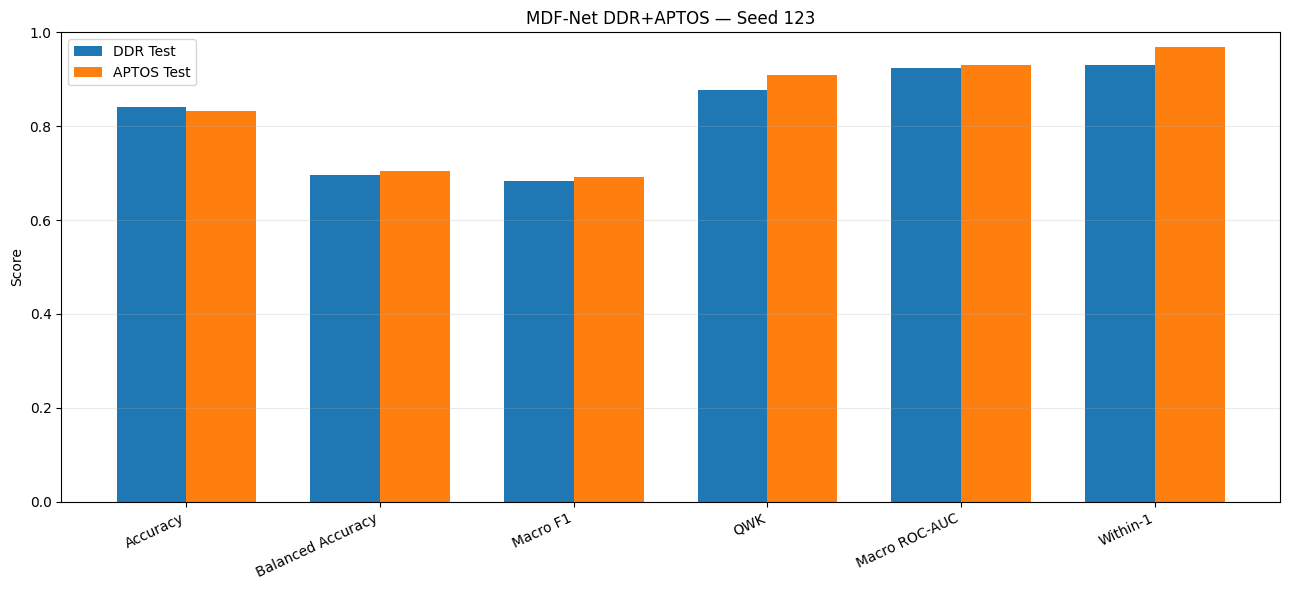

In [145]:
# ============================================================
# DDR vs APTOS — MAIN METRIC COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


graph_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "QWK",
    "Macro ROC-AUC",
    "Within-1"
]


ddr_values = [
    DDR_METRICS[m]
    for m in graph_metrics
]

aptos_values = [
    APTOS_METRICS[m]
    for m in graph_metrics
]


x = np.arange(
    len(graph_metrics)
)

width = 0.36


plt.figure(
    figsize=(13, 6)
)


plt.bar(
    x - width / 2,
    ddr_values,
    width,
    label="DDR Test"
)

plt.bar(
    x + width / 2,
    aptos_values,
    width,
    label="APTOS Test"
)


plt.xticks(
    x,
    graph_metrics,
    rotation=25,
    ha="right"
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Score"
)

plt.title(
    f"MDF-Net DDR+APTOS — Seed {CFG.SEED}"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"seed{CFG.SEED}_DDR_APTOS_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

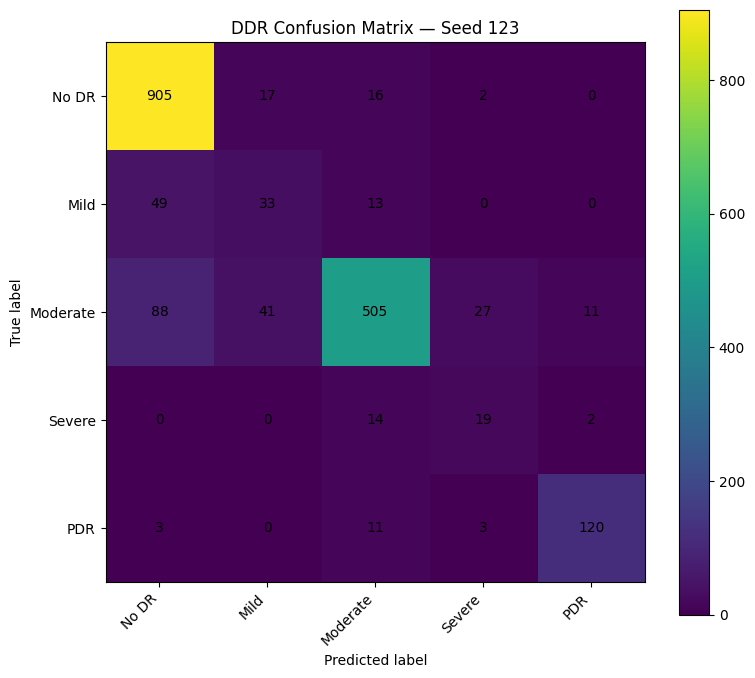

In [146]:
# ============================================================
# DDR CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np


CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "PDR"
]


ddr_true, ddr_pred, ddr_probs = (
    get_result_arrays(
        DDR_RESULT
    )
)


cm_ddr = confusion_matrix(
    ddr_true,
    ddr_pred,
    labels=[0, 1, 2, 3, 4]
)


plt.figure(
    figsize=(8, 7)
)

plt.imshow(
    cm_ddr,
    interpolation="nearest"
)

plt.title(
    f"DDR Confusion Matrix — Seed {CFG.SEED}"
)

plt.colorbar()


ticks = np.arange(
    len(CLASS_NAMES)
)

plt.xticks(
    ticks,
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks,
    CLASS_NAMES
)


threshold = (
    cm_ddr.max()
    / 2
)


for i in range(
    cm_ddr.shape[0]
):

    for j in range(
        cm_ddr.shape[1]
    ):

        plt.text(
            j,
            i,
            str(
                cm_ddr[i, j]
            ),
            ha="center",
            va="center"
        )


plt.ylabel(
    "True label"
)

plt.xlabel(
    "Predicted label"
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"DDR_confusion_matrix_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

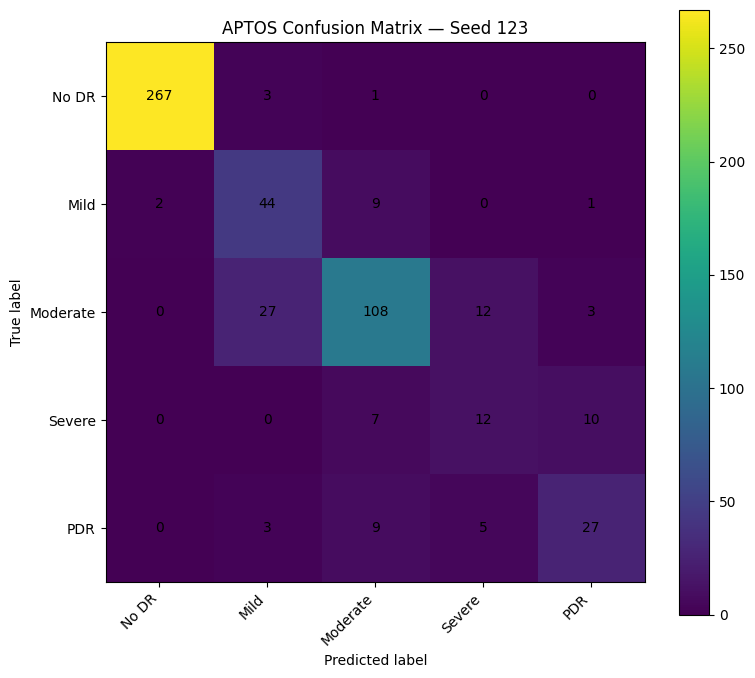

In [147]:
# ============================================================
# APTOS CONFUSION MATRIX
# ============================================================

aptos_true, aptos_pred, aptos_probs = (
    get_result_arrays(
        APTOS_RESULT
    )
)


cm_aptos = confusion_matrix(
    aptos_true,
    aptos_pred,
    labels=[0, 1, 2, 3, 4]
)


plt.figure(
    figsize=(8, 7)
)

plt.imshow(
    cm_aptos,
    interpolation="nearest"
)

plt.title(
    f"APTOS Confusion Matrix — Seed {CFG.SEED}"
)

plt.colorbar()


ticks = np.arange(
    len(CLASS_NAMES)
)

plt.xticks(
    ticks,
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks,
    CLASS_NAMES
)


for i in range(
    cm_aptos.shape[0]
):

    for j in range(
        cm_aptos.shape[1]
    ):

        plt.text(
            j,
            i,
            str(
                cm_aptos[i, j]
            ),
            ha="center",
            va="center"
        )


plt.ylabel(
    "True label"
)

plt.xlabel(
    "Predicted label"
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"APTOS_confusion_matrix_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [148]:
# ============================================================
# PER-CLASS PERFORMANCE
# ============================================================

from sklearn.metrics import classification_report


def class_report(
    y_true,
    y_pred,
    dataset_name
):

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )


    df = pd.DataFrame(
        report
    ).T


    df.to_csv(
        WORK_DIR
        / (
            f"{dataset_name}_classification_"
            f"report_seed{CFG.SEED}.csv"
        )
    )


    return df


DDR_CLASS_REPORT = class_report(
    ddr_true,
    ddr_pred,
    "DDR"
)

APTOS_CLASS_REPORT = class_report(
    aptos_true,
    aptos_pred,
    "APTOS"
)


print("DDR")
display(
    DDR_CLASS_REPORT.round(4)
)


print("\nAPTOS")
display(
    APTOS_CLASS_REPORT.round(4)
)

DDR


,precision,recall,f1-score,support
No DR,0.8660,0.9628,0.9118,940.0000
Mild,0.3626,0.3474,0.3548,95.0000
Moderate,0.9034,0.7515,0.8205,672.0000
Severe,0.3725,0.5429,0.4419,35.0000
PDR,0.9023,0.8759,0.8889,137.0000
accuracy,0.8419,0.8419,0.8419,0.8419
macro avg,0.6814,0.6961,0.6836,1879.0000
weighted avg,0.8474,0.8419,0.8406,1879.0000



APTOS


,precision,recall,f1-score,support
No DR,0.9926,0.9852,0.9889,271.0000
Mild,0.5714,0.7857,0.6617,56.0000
Moderate,0.8060,0.7200,0.7606,150.0000
Severe,0.4138,0.4138,0.4138,29.0000
PDR,0.6585,0.6136,0.6353,44.0000
accuracy,0.8327,0.8327,0.8327,0.8327
macro avg,0.6885,0.7037,0.6920,550.0000
weighted avg,0.8416,0.8327,0.8347,550.0000


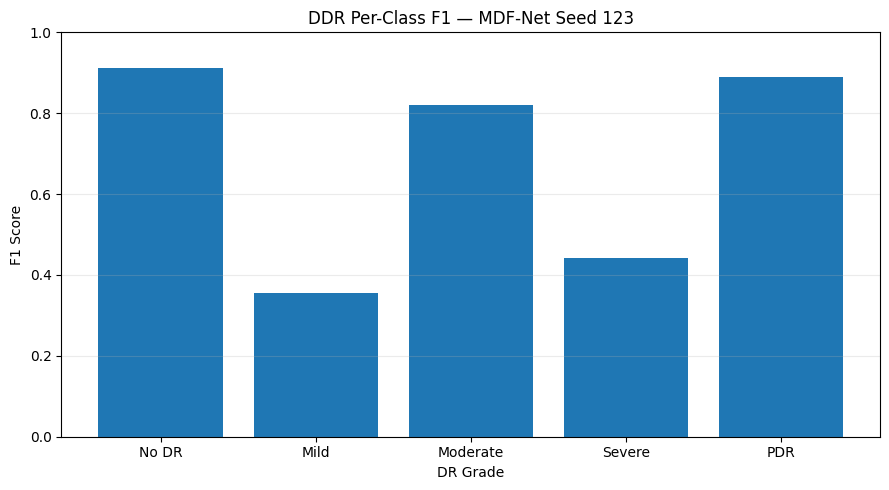

In [149]:
# ============================================================
# DDR PER-CLASS F1
# ============================================================

ddr_class_f1 = [
    DDR_CLASS_REPORT.loc[
        cls,
        "f1-score"
    ]
    for cls in CLASS_NAMES
]


plt.figure(
    figsize=(9, 5)
)

plt.bar(
    CLASS_NAMES,
    ddr_class_f1
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "F1 Score"
)

plt.xlabel(
    "DR Grade"
)

plt.title(
    f"DDR Per-Class F1 — MDF-Net Seed {CFG.SEED}"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"DDR_per_class_F1_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

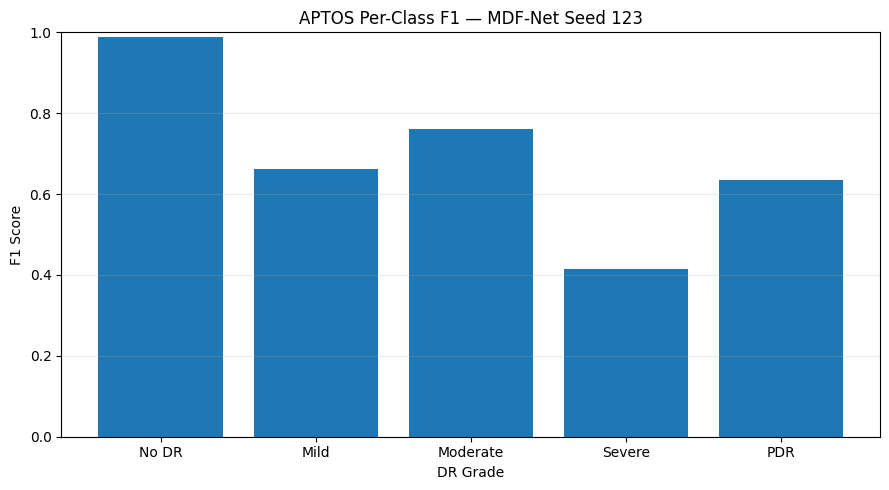

In [150]:
# ============================================================
# APTOS PER-CLASS F1
# ============================================================

aptos_class_f1 = [
    APTOS_CLASS_REPORT.loc[
        cls,
        "f1-score"
    ]
    for cls in CLASS_NAMES
]


plt.figure(
    figsize=(9, 5)
)

plt.bar(
    CLASS_NAMES,
    aptos_class_f1
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "F1 Score"
)

plt.xlabel(
    "DR Grade"
)

plt.title(
    f"APTOS Per-Class F1 — MDF-Net Seed {CFG.SEED}"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"APTOS_per_class_F1_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

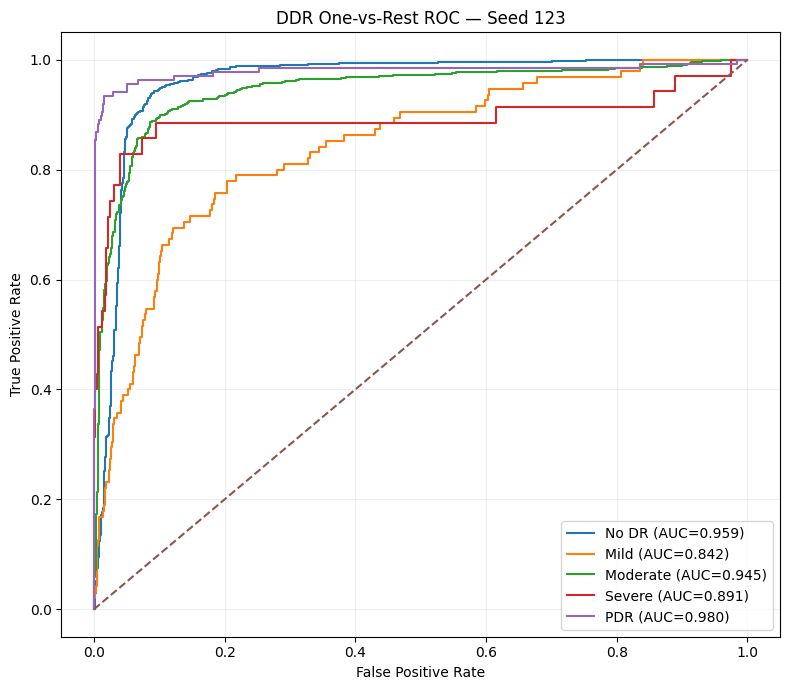

In [151]:
# ============================================================
# DDR MULTI-CLASS ROC CURVES
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc


ddr_true_bin = label_binarize(
    ddr_true,
    classes=[
        0,
        1,
        2,
        3,
        4
    ]
)


plt.figure(
    figsize=(8, 7)
)


for i in range(
    5
):

    fpr, tpr, _ = roc_curve(
        ddr_true_bin[:, i],
        ddr_probs[:, i]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.3f})"
        )
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    f"DDR One-vs-Rest ROC — Seed {CFG.SEED}"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"DDR_ROC_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

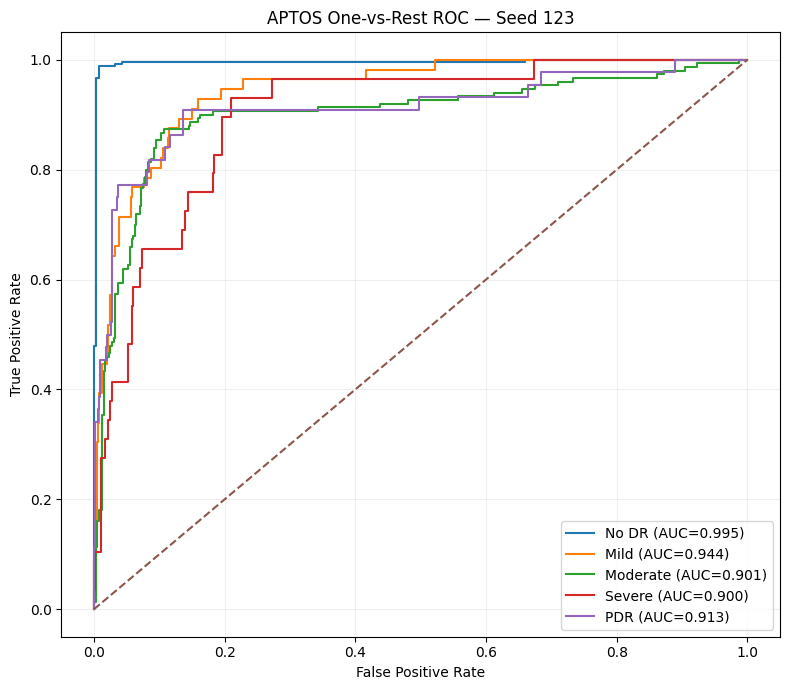

In [152]:
# ============================================================
# APTOS MULTI-CLASS ROC CURVES
# ============================================================

aptos_true_bin = label_binarize(
    aptos_true,
    classes=[
        0,
        1,
        2,
        3,
        4
    ]
)


plt.figure(
    figsize=(8, 7)
)


for i in range(
    5
):

    fpr, tpr, _ = roc_curve(
        aptos_true_bin[:, i],
        aptos_probs[:, i]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            f"{CLASS_NAMES[i]} "
            f"(AUC={roc_auc:.3f})"
        )
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    f"APTOS One-vs-Rest ROC — Seed {CFG.SEED}"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"APTOS_ROC_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [153]:
# ============================================================
# TRAINING LOSS CURVE
# ============================================================

history_files = list(
    WORK_DIR.glob(
        "*history*.csv"
    )
)


print(
    "History files:",
    history_files
)


if len(history_files) > 0:

    history_df = pd.read_csv(
        history_files[0]
    )

    display(
        history_df
    )

    print(
        "Columns:",
        history_df.columns.tolist()
    )

History files: [PosixPath('/kaggle/working/MDFNet_DDR_APTOS_seed123/training_history.csv')]


,epoch,train_loss,train_ce,train_ordinal,selection_score,ddr_val_accuracy,ddr_val_balanced_accuracy,ddr_val_macro_f1,ddr_val_qwk,ddr_val_auc,aptos_val_accuracy,aptos_val_balanced_accuracy,aptos_val_macro_f1,aptos_val_qwk,aptos_val_auc
0,1,1.160434,1.111996,0.322920,0.633284,0.680511,0.481735,0.477961,0.695805,0.858585,0.739526,0.610244,0.560246,0.799123,0.918374
1,2,1.042085,1.002478,0.264047,0.691579,0.656550,0.626768,0.512124,0.784593,0.896205,0.734062,0.649449,0.585583,0.884017,0.930144
2,3,0.816702,0.789101,0.184006,0.725466,0.764643,0.633446,0.596680,0.796405,0.899238,0.785064,0.679850,0.651924,0.856855,0.926746
3,4,0.680034,0.658253,0.145208,0.742378,0.792332,0.662082,0.611907,0.832876,0.916573,0.795993,0.670398,0.642755,0.881973,0.924728
4,5,0.613824,0.595111,0.124750,0.737223,0.775293,0.665562,0.631724,0.830217,0.916573,0.779599,0.657202,0.634145,0.852805,0.896990
5,6,0.528668,0.513664,0.100027,0.729576,0.801917,0.672159,0.649515,0.838415,0.917974,0.763206,0.628730,0.610726,0.819647,0.881707
6,7,0.483393,0.469852,0.090272,0.727513,0.749734,0.664406,0.628930,0.823801,0.899776,0.772313,0.623849,0.607694,0.849625,0.885872
7,8,0.461483,0.448966,0.083451,0.758128,0.801384,0.719089,0.674292,0.858675,0.925861,0.774135,0.656676,0.635163,0.864383,0.881862
8,9,0.410132,0.399518,0.070756,0.768319,0.824814,0.696573,0.663019,0.858883,0.931414,0.808743,0.657678,0.657041,0.894332,0.900443
9,10,0.384603,0.374983,0.064131,0.768378,0.830138,0.712686,0.680391,0.874044,0.920781,0.786885,0.654890,0.635975,0.883104,0.887297


Columns: ['epoch', 'train_loss', 'train_ce', 'train_ordinal', 'selection_score', 'ddr_val_accuracy', 'ddr_val_balanced_accuracy', 'ddr_val_macro_f1', 'ddr_val_qwk', 'ddr_val_auc', 'aptos_val_accuracy', 'aptos_val_balanced_accuracy', 'aptos_val_macro_f1', 'aptos_val_qwk', 'aptos_val_auc']


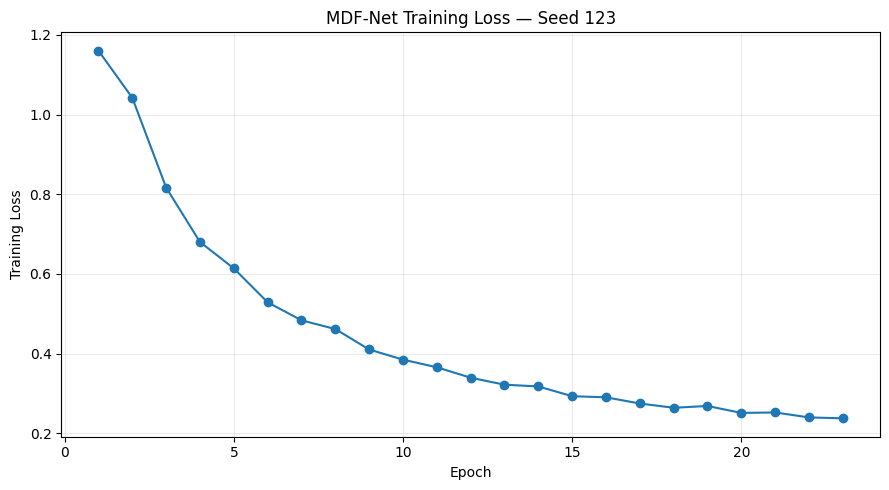

In [154]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Training Loss"
)

plt.title(
    f"MDF-Net Training Loss — Seed {CFG.SEED}"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"training_loss_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

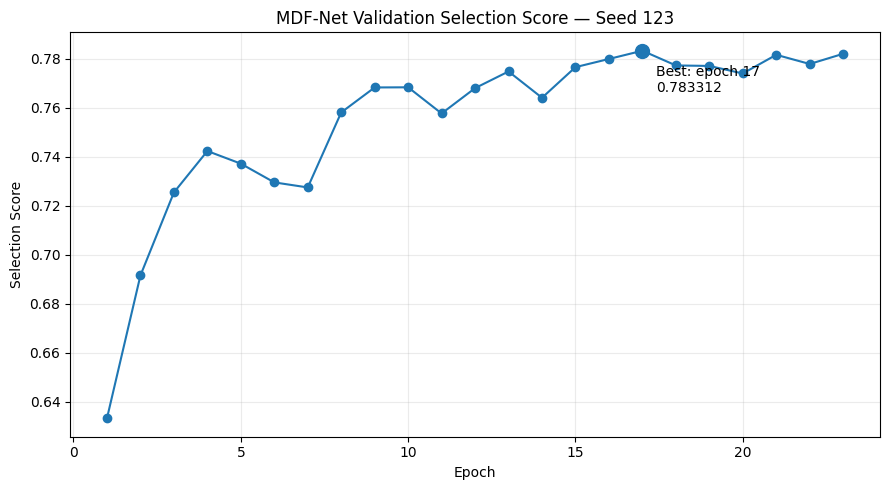

Best epoch: 17
Best selection score: 0.7833123282666278


In [155]:
# ============================================================
# VALIDATION SELECTION SCORE
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["selection_score"],
    marker="o"
)


best_idx = (
    history_df[
        "selection_score"
    ].idxmax()
)

best_epoch = history_df.loc[
    best_idx,
    "epoch"
]

best_score = history_df.loc[
    best_idx,
    "selection_score"
]


plt.scatter(
    best_epoch,
    best_score,
    s=100,
    zorder=5
)


plt.annotate(
    (
        f"Best: epoch {int(best_epoch)}\n"
        f"{best_score:.6f}"
    ),
    (
        best_epoch,
        best_score
    ),
    xytext=(10, -30),
    textcoords="offset points"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Selection Score"
)

plt.title(
    f"MDF-Net Validation Selection Score — Seed {CFG.SEED}"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"selection_score_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Best epoch:",
    int(best_epoch)
)

print(
    "Best selection score:",
    best_score
)

In [94]:
print(history_df.columns.tolist())

['epoch', 'train_loss', 'train_ce', 'train_ordinal', 'selection_score', 'ddr_val_accuracy', 'ddr_val_balanced_accuracy', 'ddr_val_macro_f1', 'ddr_val_qwk', 'ddr_val_auc', 'aptos_val_accuracy', 'aptos_val_balanced_accuracy', 'aptos_val_macro_f1', 'aptos_val_qwk', 'aptos_val_auc']


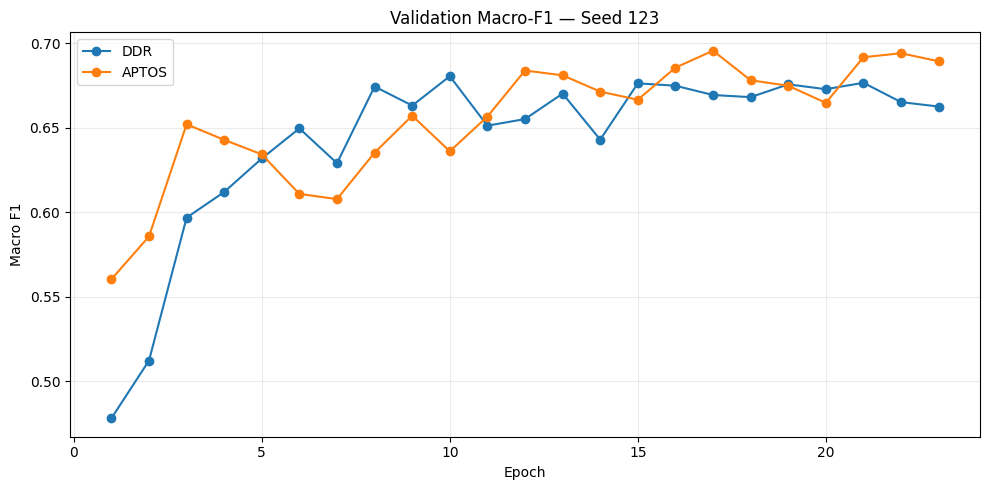

In [156]:
# ============================================================
# VALIDATION MACRO-F1 CURVES
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["ddr_val_macro_f1"],
    marker="o",
    label="DDR"
)

plt.plot(
    history_df["epoch"],
    history_df["aptos_val_macro_f1"],
    marker="o",
    label="APTOS"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Macro F1"
)

plt.title(
    f"Validation Macro-F1 — Seed {CFG.SEED}"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"validation_F1_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

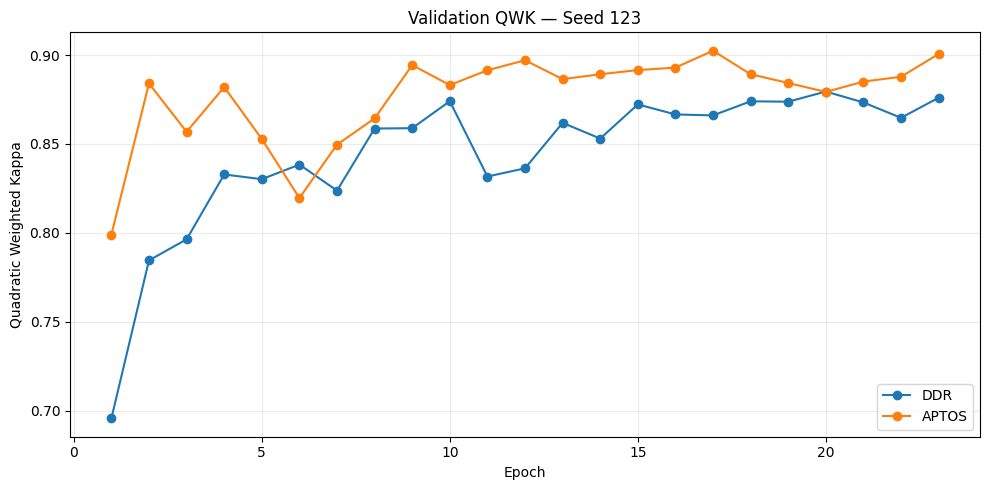

In [157]:
# ============================================================
# VALIDATION QWK CURVES
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["ddr_val_qwk"],
    marker="o",
    label="DDR"
)

plt.plot(
    history_df["epoch"],
    history_df["aptos_val_qwk"],
    marker="o",
    label="APTOS"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Quadratic Weighted Kappa"
)

plt.title(
    f"Validation QWK — Seed {CFG.SEED}"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"validation_QWK_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [158]:
# ============================================================
# BOOTSTRAP 95% CI RESULTS
# ============================================================

print(
    "DDR — 95% Confidence Intervals"
)

display(
    DDR_BOOTSTRAP.round(6)
)


print(
    "\nAPTOS — 95% Confidence Intervals"
)

display(
    APTOS_BOOTSTRAP.round(6)
)

DDR — 95% Confidence Intervals


,metric,estimate,ci_lower,ci_upper,valid_reps
0,accuracy,0.841937,0.826503,0.856307,2000
1,balanced_accuracy,0.696078,0.657498,0.736568,2000
2,macro_precision,0.681374,0.651087,0.715311,2000
3,macro_recall,0.696078,0.657498,0.736568,2000
4,macro_f1,0.683580,0.650957,0.717357,2000
5,qwk,0.877059,0.858975,0.893915,2000
6,macro_auc,0.923316,0.902779,0.942554,2000
7,mae,0.232038,0.207557,0.258116,2000
8,within_1,0.930282,0.918574,0.941458,2000
9,major_error_rate,0.069718,0.058542,0.081426,2000



APTOS — 95% Confidence Intervals


,metric,estimate,ci_lower,ci_upper,valid_reps
0,accuracy,0.832727,0.803636,0.860000,2000
1,balanced_accuracy,0.703677,0.648189,0.757368,2000
2,macro_precision,0.688459,0.636002,0.742675,2000
3,macro_recall,0.703677,0.648189,0.757368,2000
4,macro_f1,0.692039,0.637561,0.743257,2000
5,qwk,0.909918,0.882267,0.932873,2000
6,macro_auc,0.930640,0.909801,0.949741,2000
7,mae,0.205455,0.169091,0.245500,2000
8,within_1,0.969091,0.956364,0.981818,2000
9,major_error_rate,0.030909,0.018182,0.043636,2000


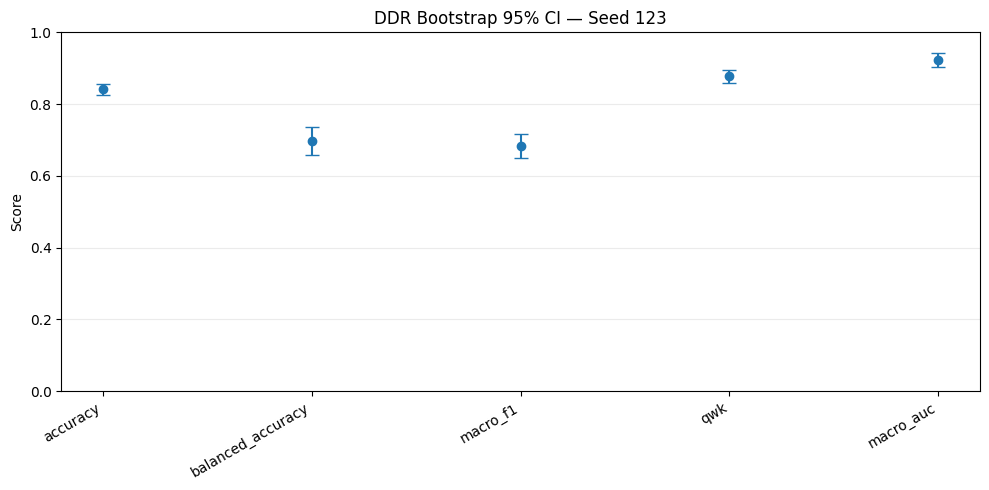

In [159]:
# ============================================================
# DDR BOOTSTRAP 95% CI GRAPH
# ============================================================

ddr_ci = DDR_BOOTSTRAP.copy()


ddr_ci = ddr_ci[
    ddr_ci["metric"].isin(
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "qwk",
            "macro_auc"
        ]
    )
].reset_index(
    drop=True
)


x = np.arange(
    len(ddr_ci)
)


lower_error = (
    ddr_ci["estimate"]
    -
    ddr_ci["ci_lower"]
)

upper_error = (
    ddr_ci["ci_upper"]
    -
    ddr_ci["estimate"]
)


plt.figure(
    figsize=(10, 5)
)

plt.errorbar(
    x,
    ddr_ci["estimate"],
    yerr=[
        lower_error,
        upper_error
    ],
    fmt="o",
    capsize=5
)

plt.xticks(
    x,
    ddr_ci["metric"],
    rotation=30,
    ha="right"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    f"DDR Bootstrap 95% CI — Seed {CFG.SEED}"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"DDR_bootstrap_CI_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

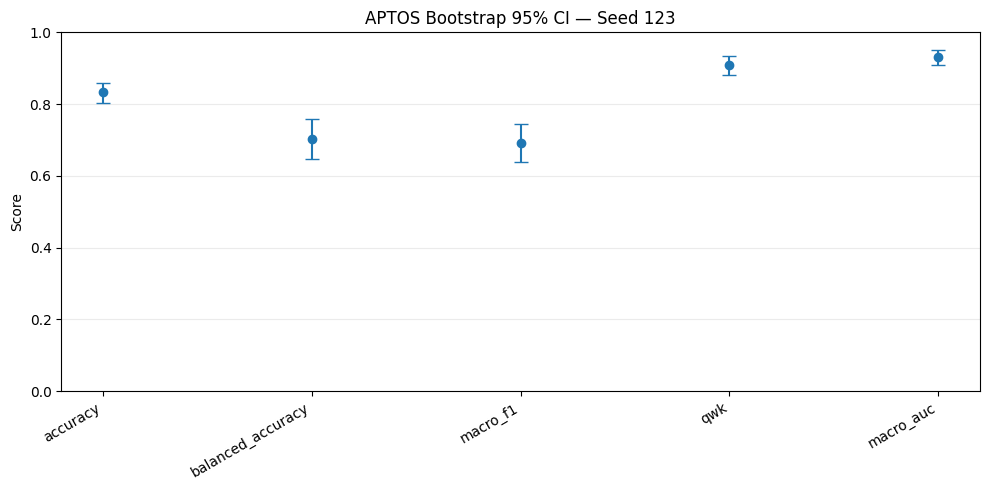

In [160]:
# ============================================================
# APTOS BOOTSTRAP 95% CI GRAPH
# ============================================================

aptos_ci = APTOS_BOOTSTRAP.copy()


aptos_ci = aptos_ci[
    aptos_ci["metric"].isin(
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "qwk",
            "macro_auc"
        ]
    )
].reset_index(
    drop=True
)


x = np.arange(
    len(aptos_ci)
)


lower_error = (
    aptos_ci["estimate"]
    -
    aptos_ci["ci_lower"]
)

upper_error = (
    aptos_ci["ci_upper"]
    -
    aptos_ci["estimate"]
)


plt.figure(
    figsize=(10, 5)
)

plt.errorbar(
    x,
    aptos_ci["estimate"],
    yerr=[
        lower_error,
        upper_error
    ],
    fmt="o",
    capsize=5
)

plt.xticks(
    x,
    aptos_ci["metric"],
    rotation=30,
    ha="right"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    f"APTOS Bootstrap 95% CI — Seed {CFG.SEED}"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    WORK_DIR
    / f"APTOS_bootstrap_CI_seed{CFG.SEED}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()